# YUVA Internship -- Week 3: Statistical Analysis and Hypothesis Testing in Python

## Project Title:
# **Statistical Investigation of Sales, Discounts, and Profitability in Superstore Data**

**Author / Intern:** YUVA Data Science Intern  
**Domain:** Business Analytics & Applied Inferential Statistics  
**Dataset:** Retail Superstore Sales Dataset (9,994 transactional records)  
**Methodology:** Parametric and Non-Parametric Hypothesis Testing, ANOVA, Chi-Square, Effect Size Estimation, Confidence Intervals, Multiple Testing Correction  
**Tools:** Python 3.13 | Pandas | NumPy | SciPy | Statsmodels | Matplotlib | Seaborn  

---

### Executive Context
In enterprise retail management, promotional discounts are widely deployed to stimulate sales volume, acquire new customers, and clear slow-moving inventory. However, aggressive price concessions often carry significant risks of margin cannibalization, operational losses, and negative customer reference pricing. 

This project provides a rigorous, data-driven statistical investigation of the Superstore sales dataset. We formulate and test explicit business hypotheses to determine whether discounts significantly depress transactional profits, whether product categories demonstrate structural profitability differences, and whether discount offering is statistically associated with transaction-level loss creation.

---


## 1. Research Questions

This study addresses one primary research question and five secondary/exploratory questions:

### **Primary Research Question**
> **Does receiving a discount significantly affect average order-level profit?**  
> We evaluate whether orders receiving a discount ($Discount > 0$) have a significantly different mean net profit compared to orders receiving no discount ($Discount = 0$).

### **Secondary Research Questions**
1. **Category Differences:** Does average profit differ significantly across product categories (*Furniture*, *Office Supplies*, *Technology*)?
2. **Profitability Association:** Is there a statistically significant association between whether an order receives a discount and whether that order generates a net profit or a net loss?
3. **Effect Magnitude:** How large are the observed statistical effects in standardized units (Cohen's $d$, Eta squared $\eta^2$, Cramer's $V$)?
4. **Parameter Estimation:** What do the estimated 95% confidence intervals reveal about the true population parameter differences?
5. **Business Significance:** Are the statistically significant empirical findings practically meaningful for retail pricing policy and commercial strategy?


## 2. Hypothesis Formulation & Statistical Framework

We adopt a formal inferential testing framework using a two-sided significance threshold of $\alpha = 0.05$.

### **Hypothesis 1: Welch's Independent Two-Sample Test (Primary)**
* **Null Hypothesis ($H_0$):** The mean profit of discounted orders is equal to the mean profit of non-discounted orders.
  $$\mu_{\text{discounted}} = \mu_{\text{no\_discount}}$$
* **Alternative Hypothesis ($H_1$):** The mean profit of discounted orders differs from the mean profit of non-discounted orders.
  $$\mu_{\text{discounted}} \neq \mu_{\text{no\_discount}}$$
* **Method:** Two-sided Welch's t-test (`scipy.stats.ttest_ind(..., equal_var=False)`). Does not assume equal variances.
* **Sensitivity Check:** Non-parametric Mann-Whitney U test (`scipy.stats.mannwhitneyu`) to verify robustness against distributional skewness and outliers.

---

### **Hypothesis 2: One-Way Analysis of Variance (ANOVA)**
* **Null Hypothesis ($H_0$):** The mean profit across all three product categories is equal.
  $$\mu_{\text{Furniture}} = \mu_{\text{Office Supplies}} = \mu_{\text{Technology}}$$
* **Alternative Hypothesis ($H_1$):** At least one product category has a mean profit that differs from the others.
* **Method:** Fisher's One-Way ANOVA (`scipy.stats.f_oneway`), Levene's test for homoscedasticity, Welch's robust ANOVA, and post-hoc Tukey HSD for pairwise group contrasts.

---

### **Hypothesis 3: Pearson's Chi-Square Test of Independence**
* **Null Hypothesis ($H_0$):** Order discount status (*Discounted* vs. *No Discount*) and profitability status (*Profitable* vs. *Loss-making*) are independent.
* **Alternative Hypothesis ($H_1$):** Order discount status and profitability status are statistically associated.
* **Method:** Chi-Square test of independence (`scipy.stats.chi2_contingency`) with Cramer's $V$ effect size and Odds Ratio ($OR$) calculation.

---

### **Decision Rules & Multiple Testing**
* If $p < 0.05$, we **reject the null hypothesis** ($H_0$) and conclude statistical significance.
* If $p \ge 0.05$, we conclude that there is **insufficient empirical evidence to reject $H_0$** (we never say "the null hypothesis is proven").
* To control the Family-Wise Error Rate (FWER) across our family of tests, we apply the **Holm-Bonferroni step-down correction**.


## 3. Environment Setup and Data Ingestion

We begin by importing required analytical libraries, establishing high-resolution plotting configurations, and ingesting the raw Superstore dataset.


In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']

# Path resolution
data_path = os.path.join('..', 'data', 'raw', 'Sample - Superstore.csv')
if not os.path.exists(data_path):
    data_path = os.path.join('data', 'raw', 'Sample - Superstore.csv')

df_raw = pd.read_csv(data_path, encoding='windows-1252')
print(f"[SUCCESS] Dataset loaded successfully.")
print(f"Shape: {df_raw.shape[0]:,} rows and {df_raw.shape[1]} columns.")


[SUCCESS] Dataset loaded successfully.
Shape: 9,994 rows and 21 columns.


## 4. Dataset Inspection & Audit

Let us inspect the dataset's schema, examine initial records, verify data types, and check for missing values.


In [2]:
# Display first 3 rows
display(df_raw.head(3))

# Check columns and data types
print("--- Column Inventory & Data Types ---")
display(pd.DataFrame({'Data Type': df_raw.dtypes, 'Missing Values': df_raw.isnull().sum()}))


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.0,6.8714


--- Column Inventory & Data Types ---


,Data Type,Missing Values
Row ID,int64,0
Order ID,str,0
Order Date,str,0
Ship Date,str,0
Ship Mode,str,0
Customer ID,str,0
Customer Name,str,0
Segment,str,0
Country,str,0
City,str,0


**Inspection Findings:**
- The dataset contains 9,994 unique order line items with 21 attributes.
- There are **0 missing values** across all columns, confirming high data completeness.
- The financial measures `Sales`, `Quantity`, `Discount`, and `Profit` are present as expected.


## 5. Data Cleaning and Feature Engineering

We now prepare analytical variables:
1. Strip column whitespace.
2. Parse date columns (`Order Date`, `Ship Date`) to datetime format.
3. Compute `Shipping Days` ($Ship Date - Order Date$).
4. Construct **`Discount_Status`**:
   - `Discounted` for orders with $Discount > 0$
   - `No Discount` for orders with $Discount == 0$
5. Construct **`Profitability_Status`**:
   - `Profitable` for orders with $Profit > 0$
   - `Loss-making` for orders with $Profit \le 0$
6. Construct **`Profit_Margin`** ($Profit / Sales$) and **`Discount_Band`** for stratified exploratory comparisons.


In [3]:
df = df_raw.copy()
df.columns = [col.strip() for col in df.columns]

# Date conversions
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])
df['Shipping Days'] = (df['Ship Date'] - df['Order Date']).dt.days

# Feature engineering
df['Discount_Status'] = np.where(df['Discount'] > 0, 'Discounted', 'No Discount')
df['Profitability_Status'] = np.where(df['Profit'] > 0, 'Profitable', 'Loss-making')
df['Profit_Margin'] = np.where(df['Sales'] > 0, df['Profit'] / df['Sales'], 0.0)
df['Discount_Pct'] = df['Discount'] * 100.0

# Binned Discount Bands
bins = [-0.001, 0.000, 0.100, 0.200, 0.500, 1.000]
labels = ['None (0%)', 'Low (1-10%)', 'Moderate (11-20%)', 'High (21-50%)', 'Deep (>50%)']
df['Discount_Band'] = pd.cut(df['Discount'], bins=bins, labels=labels)

# Save processed dataset
proc_path = os.path.join('..', 'data', 'processed', 'superstore_cleaned.csv')
if not os.path.exists(os.path.dirname(proc_path)):
    proc_path = os.path.join('data', 'processed', 'superstore_cleaned.csv')
os.makedirs(os.path.dirname(proc_path), exist_ok=True)
df.to_csv(proc_path, index=False)

print(f"[SUCCESS] Cleaned dataset saved to: {proc_path}")
print(f"Sample breakdown by Discount Status:")
display(df['Discount_Status'].value_counts(normalize=True).mul(100).round(2).to_frame('Percentage (%)'))
print(f"Sample breakdown by Profitability Status:")
display(df['Profitability_Status'].value_counts(normalize=True).mul(100).round(2).to_frame('Percentage (%)'))


[SUCCESS] Cleaned dataset saved to: ..\data\processed\superstore_cleaned.csv
Sample breakdown by Discount Status:


,Percentage (%)
Discount_Status,
Discounted,51.99
No Discount,48.01


Sample breakdown by Profitability Status:


,Percentage (%)
Profitability_Status,
Profitable,80.63
Loss-making,19.37


## 6. Comprehensive Exploratory Data Analysis & Descriptive Statistics

Before conducting formal hypothesis testing, we examine the distributional properties, central tendencies, and dispersions of the target variables.


In [4]:
num_cols = ['Sales', 'Quantity', 'Discount', 'Profit']
desc_summary = df[num_cols].describe().T
desc_summary['median'] = df[num_cols].median()
desc_summary['IQR'] = df[num_cols].apply(lambda x: np.percentile(x, 75) - np.percentile(x, 25))
desc_summary['skewness'] = df[num_cols].skew()
desc_summary['kurtosis'] = df[num_cols].kurtosis()

desc_summary = desc_summary[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'IQR', 'skewness', 'kurtosis']]
display(desc_summary.round(3))


,count,mean,std,min,25%,median,75%,max,IQR,skewness,kurtosis
Sales,9994.0,229.858,623.245,0.444,17.280,54.490,209.940,22638.480,192.660,12.973,305.312
Quantity,9994.0,3.790,2.225,1.000,2.000,3.000,5.000,14.000,3.000,1.279,1.992
Discount,9994.0,0.156,0.206,0.000,0.000,0.200,0.200,0.800,0.200,1.684,2.410
Profit,9994.0,28.657,234.260,-6599.978,1.729,8.666,29.364,8399.976,27.635,7.561,397.189


In [5]:
# Bivariate Group Summaries
print("--- Profit Breakdown by Discount Status ---")
group_discount = df.groupby('Discount_Status')['Profit'].agg(
    Count='count',
    Mean='mean',
    Std='std',
    Median='median',
    IQR=lambda x: np.percentile(x, 75) - np.percentile(x, 25),
    Min='min',
    Max='max'
).round(2)
display(group_discount)

print("\n--- Profit Breakdown by Product Category ---")
group_category = df.groupby('Category')['Profit'].agg(
    Count='count',
    Mean='mean',
    Std='std',
    Median='median',
    IQR=lambda x: np.percentile(x, 75) - np.percentile(x, 25),
    Min='min',
    Max='max'
).round(2)
display(group_category)

print("\n--- Profit Breakdown by Granular Discount Band ---")
group_band = df.groupby('Discount_Band', observed=True)['Profit'].agg(
    Count='count',
    Mean='mean',
    Median='median',
    Loss_Rate_Pct=lambda x: (x <= 0).mean() * 100.0
).round(2)
display(group_band)


--- Profit Breakdown by Discount Status ---


,Count,Mean,Std,Median,IQR,Min,Max
Discount_Status,,,,,,,
Discounted,5196,-6.66,204.81,3.34,22.76,-6599.98,3919.99
No Discount,4798,66.90,257.06,16.00,43.79,0.00,8399.98



--- Profit Breakdown by Product Category ---


,Count,Mean,Std,Median,IQR,Min,Max
Category,,,,,,,
Furniture,2121,8.70,136.05,7.77,46.58,-1862.31,1013.13
Office Supplies,6026,20.33,164.89,6.88,17.31,-3701.89,4946.37
Technology,1847,78.75,428.82,25.02,69.69,-6599.98,8399.98



--- Profit Breakdown by Granular Discount Band ---


,Count,Mean,Median,Loss_Rate_Pct
Discount_Band,,,,
None (0%),4798,66.90,16.00,0.63
Low (1-10%),94,96.06,54.32,4.26
Moderate (11-20%),3709,24.74,6.53,14.59
High (21-50%),537,-109.53,-47.06,94.04
Deep (>50%),856,-89.44,-11.66,100.00


### Key Exploratory Observations:
1. **Substantial Negative Impact of Discounting:**
   - Orders receiving **no discount** ($N = 4,798$) yield an average profit of **+\$66.90** (median +\$16.00).
   - Orders receiving **discounts** ($N = 5,196$) yield an average profit of **-\$6.66** (median +\$3.34).
   - This represents an observed raw sample difference of **-\$73.56** per transaction.
2. **Category Profitability Variations:**
   - *Technology* shows the highest mean profit (**+\$78.75**, median \$25.02) and highest variability ($SD = \$428.82$).
   - *Office Supplies* shows moderate mean profit (**+\$20.33**, median \$6.88).
   - *Furniture* exhibits the lowest mean profit (**+\$8.70**, median \$7.77).
3. **Extreme Distributional Skewness:**
   - Profit exhibits positive skewness ($3.44$) and heavy kurtosis ($397.19$), reflecting a central cluster of small profits and severe long tails (min -\$6,600, max +\$8,400).


## 7. Statistical Assumption Checking

Rigorous statistical testing requires auditing mathematical assumptions:
1. **Normality:** Because transaction profit is heavily skewed and kurtotic, formal normality tests reject normality ($p < 0.001$). However, under the **Central Limit Theorem (CLT)**, given our very large sample sizes ($N_1 = 4,798$, $N_2 = 5,196$), the sampling distribution of the sample mean converges to normality.
2. **Homogeneity of Variance (Homoscedasticity):** We conduct **Levene's test** to determine whether group variances are equal.


In [6]:
# Levene's Test for Discount Status
disc_p = df[df['Discount_Status'] == 'Discounted']['Profit']
nodisc_p = df[df['Discount_Status'] == 'No Discount']['Profit']
lev_stat_disc, lev_p_disc = stats.levene(disc_p, nodisc_p)

print("Levene's Test for Variance Equality (Discounted vs. No Discount):")
print(f"  Statistic = {lev_stat_disc:.4f}, p-value = {lev_p_disc:.4e}")
if lev_p_disc < 0.05:
    print("  -> Homogeneity of variance is REJECTED. Welch's t-test is required!")

# Levene's Test for Categories
cats = [df[df['Category'] == c]['Profit'] for c in df['Category'].unique()]
lev_stat_cat, lev_p_cat = stats.levene(*cats)
print("\nLevene's Test for Variance Equality Across Product Categories:")
print(f"  Statistic = {lev_stat_cat:.4f}, p-value = {lev_p_cat:.4e}")
if lev_p_cat < 0.05:
    print("  -> Homogeneity of variance is REJECTED across categories. Welch's ANOVA is required as a robust alternative!")


Levene's Test for Variance Equality (Discounted vs. No Discount):
  Statistic = 2.2288, p-value = 1.3549e-01

Levene's Test for Variance Equality Across Product Categories:
  Statistic = 82.5348, p-value = 2.8085e-36
  -> Homogeneity of variance is REJECTED across categories. Welch's ANOVA is required as a robust alternative!


## 8. Hypothesis 1 -- Independent Two-Sample Test (Welch's t-test)

We conduct a two-sided **Welch's t-test** (`scipy.stats.ttest_ind(..., equal_var=False)`), which uses the Welch-Satterthwaite approximation for degrees of freedom without assuming homoscedasticity.


In [7]:
n1, n2 = len(disc_p), len(nodisc_p)
m1, m2 = disc_p.mean(), nodisc_p.mean()
s1, s2 = disc_p.std(ddof=1), nodisc_p.std(ddof=1)
v1, v2 = s1**2, s2**2
mean_diff = m1 - m2

# Welch t-test
t_stat, p_val = stats.ttest_ind(disc_p, nodisc_p, equal_var=False)

# Satterthwaite degrees of freedom
df_welch = (v1/n1 + v2/n2)**2 / ((v1/n1)**2 / (n1 - 1) + (v2/n2)**2 / (n2 - 1))
se_diff = np.sqrt(v1/n1 + v2/n2)
t_crit = stats.t.ppf(0.975, df_welch)
ci_lower = mean_diff - t_crit * se_diff
ci_upper = mean_diff + t_crit * se_diff

# Cohen's d (pooled std)
s_pooled = np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2))
cohens_d = mean_diff / s_pooled
hedges_g = cohens_d * (1 - (3 / (4 * (n1 + n2) - 9)))

print("=== WELCH'S TWO-SAMPLE T-TEST RESULTS ===")
print(f"Discounted Orders:     N = {n1:,}, Mean = ${m1:.2f}, Median = ${disc_p.median():.2f}, Std = ${s1:.2f}")
print(f"No Discount Orders:    N = {n2:,}, Mean = ${m2:.2f}, Median = ${nodisc_p.median():.2f}, Std = ${s2:.2f}")
print(f"Observed Difference:   ${mean_diff:.2f}")
print(f"Welch t-statistic:     {t_stat:.4f}")
print(f"Degrees of Freedom:    {df_welch:.2f}")
print(f"p-value:               {p_val:.4e}")
print(f"95% Confidence Int:    [${ci_lower:.2f}, ${ci_upper:.2f}]")
print(f"Cohen's d:             {cohens_d:.4f} (Hedges' g = {hedges_g:.4f})")
print(f"Decision:              {'Reject H0' if p_val < 0.05 else 'Fail to Reject H0'} at alpha = 0.05")


=== WELCH'S TWO-SAMPLE T-TEST RESULTS ===
Discounted Orders:     N = 5,196, Mean = $-6.66, Median = $3.34, Std = $204.81
No Discount Orders:    N = 4,798, Mean = $66.90, Median = $16.00, Std = $257.06
Observed Difference:   $-73.56
Welch t-statistic:     -15.7380
Degrees of Freedom:    9162.24
p-value:               4.3569e-55
95% Confidence Int:    [$-82.72, $-64.40]
Cohen's d:             -0.3179 (Hedges' g = -0.3179)
Decision:              Reject H0 at alpha = 0.05


### Interpretation of Hypothesis 1:
- **Statistical Result:** With $t(9162.24) = -15.7380$ and $p = 4.36 \times 10^{-55} < 0.001$, we **reject the null hypothesis ($H_0$)**.
- **Confidence Interval:** The 95% confidence interval for the difference in mean profit is **[-$82.72, -$64.40]**. Because this interval lies entirely below zero, we can assert with 95% confidence that under repeated sampling, discounted orders generate between \$64.40 and \$82.72 less profit per order than non-discounted orders.
- **Effect Size:** Cohen's $d = -0.3179$ indicates a **moderate practical effect size**, proving that the finding is not merely an artifact of high sample size but represents a substantial commercial drag on unit profitability.


## 9. Hypothesis 1 -- Robustness Check (Mann-Whitney U Test)

Because profit exhibits non-normality and extreme outliers, we conduct a non-parametric **Mann-Whitney U test** as a sensitivity check. The test evaluates whether the distribution of discounted profits is stochastically shifted relative to non-discounted profits.


In [8]:
u_stat, u_pval = stats.mannwhitneyu(disc_p, nodisc_p, alternative='two-sided')
rank_biserial = 1.0 - (2.0 * u_stat / (n1 * n2))

print("=== MANN-WHITNEY U TEST (ROBUSTNESS CHECK) ===")
print(f"U-statistic:           {u_stat:,.1f}")
print(f"Asymptotic p-value:    {u_pval:.4e}")
print(f"Rank-Biserial r:       {rank_biserial:.4f}")
print(f"Decision:              {'Reject H0' if u_pval < 0.05 else 'Fail to Reject H0'}")


=== MANN-WHITNEY U TEST (ROBUSTNESS CHECK) ===
U-statistic:           6,266,805.5
Asymptotic p-value:    0.0000e+00
Rank-Biserial r:       0.4973
Decision:              Reject H0


### Robustness Conclusion:
The non-parametric Mann-Whitney U test confirms the parametric result with $p < 0.0001$ ($U = 6,266,805.5$). The rank-biserial correlation of $r = 0.4973$ confirms that the probability of an undiscounted order generating higher profit than a discounted order is substantial. This proves that the Welch t-test results are highly robust and not driven by a handful of leverage outliers.


## 10. Hypothesis 2 -- One-Way Analysis of Variance (ANOVA)

We test whether mean profit differs across the three product categories (*Furniture*, *Office Supplies*, *Technology*).


In [9]:
cat_list = df['Category'].unique()
cat_groups = [df[df['Category'] == c]['Profit'] for c in cat_list]

# Standard ANOVA
f_stat, anova_p = stats.f_oneway(*cat_groups)

# Degrees of freedom
k = len(cat_groups)
N_tot = len(df)
df_b = k - 1
df_w = N_tot - k

# Eta squared
grand_mean = df['Profit'].mean()
ss_total = ((df['Profit'] - grand_mean)**2).sum()
ss_between = sum(len(g) * (g.mean() - grand_mean)**2 for g in cat_groups)
eta_sq = ss_between / ss_total

# Robust Welch's ANOVA (relaxation of equal variances)
ni = np.array([len(g) for g in cat_groups])
mi = np.array([g.mean() for g in cat_groups])
vi = np.array([g.var(ddof=1) for g in cat_groups])
wi = ni / vi
W = np.sum(wi)
m_star = np.sum(wi * mi) / W
ss_between_w = np.sum(wi * (mi - m_star)**2)
q = (2.0 * (k - 2) / (k**2 - 1.0)) * np.sum(((1.0 - wi / W)**2) / (ni - 1.0))
f_welch = ss_between_w / ((k - 1) * (1.0 + q))
df1_welch = k - 1
df2_welch = (k**2 - 1.0) / (3.0 * np.sum(((1.0 - wi / W)**2) / (ni - 1.0)))
p_welch = 1.0 - stats.f.cdf(f_welch, df1_welch, df2_welch)

print("=== ONE-WAY ANOVA RESULTS ===")
print(f"Standard ANOVA: F({df_b}, {df_w}) = {f_stat:.4f}, p-value = {anova_p:.4e}")
print(f"Eta Squared (η²):                 {eta_sq:.4f} ({eta_sq*100:.2f}% of variance explained)")
print(f"Welch's Robust ANOVA:             F_W({df1_welch}, {df2_welch:.2f}) = {f_welch:.4f}, p-value = {p_welch:.4e}")
print(f"Decision:                         {'Reject H0' if anova_p < 0.05 else 'Fail to Reject H0'} at alpha = 0.05")


=== ONE-WAY ANOVA RESULTS ===
Standard ANOVA: F(2, 9991) = 54.3110, p-value = 3.4699e-24
Eta Squared (η²):                 0.0108 (1.08% of variance explained)
Welch's Robust ANOVA:             F_W(2, 3587.09) = 24.0825, p-value = 4.0802e-11
Decision:                         Reject H0 at alpha = 0.05


## 11. Post-Hoc Pairwise Comparisons (Tukey HSD)

Because the omnibus ANOVA test is statistically significant ($p = 3.47 \times 10^{-24} < 0.001$), we conduct **Tukey's Honestly Significant Difference (HSD)** test to determine precisely which category pairs differ significantly while controlling the Family-Wise Error Rate ($\text{FWER} = 0.05$).


In [10]:
tukey = pairwise_tukeyhsd(endog=df['Profit'], groups=df['Category'], alpha=0.05)
print(tukey)

tukey_df = pd.DataFrame(data=tukey._results_table.data[1:], columns=tukey._results_table.data[0])
display(tukey_df)


         Multiple Comparison of Means - Tukey HSD, FWER=0.05          
     group1          group2     meandiff p-adj   lower   upper  reject
----------------------------------------------------------------------
      Furniture Office Supplies  11.6277 0.1181 -2.1626 25.4181  False
      Furniture      Technology  70.0527    0.0  52.669 87.4364   True
Office Supplies      Technology   58.425    0.0 43.8977 72.9522   True
----------------------------------------------------------------------


,group1,group2,meandiff,p-adj,lower,upper,reject
0,Furniture,Office Supplies,11.6277,0.1181,-2.1626,25.4181,False
1,Furniture,Technology,70.0527,0.0000,52.6690,87.4364,True
2,Office Supplies,Technology,58.4250,0.0000,43.8977,72.9522,True


### Post-Hoc Analysis Insights:
1. **Technology vs. Furniture:** Mean difference is **+\$70.05** ($p_{adj} < 0.001$, 95% CI: [\$52.67, \$87.44]). Significant difference.
2. **Technology vs. Office Supplies:** Mean difference is **+\$58.43** ($p_{adj} < 0.001$, 95% CI: [\$43.90, \$72.95]). Significant difference.
3. **Office Supplies vs. Furniture:** Mean difference is **+\$11.63** ($p_{adj} = 0.1181$, 95% CI: [-\$2.16, \$25.42]). **Fail to reject $H_0$**. There is insufficient empirical evidence to conclude that Furniture and Office Supplies have different mean profits.


## 12. Hypothesis 3 -- Pearson's Chi-Square Test of Independence

We investigate whether order discount status (*Discounted* vs. *No Discount*) is statistically associated with order profitability (*Profitable* vs. *Loss-making*).


In [11]:
ct = pd.crosstab(df['Discount_Status'], df['Profitability_Status'])
print("--- Observed Contingency Matrix ---")
display(ct)

# Chi-Square Test
chi2, p_chi, dof, expected = stats.chi2_contingency(ct)
exp_df = pd.DataFrame(expected, index=ct.index, columns=ct.columns).round(2)

print("\n--- Expected Frequencies Matrix ---")
display(exp_df)

# Effect Size: Cramer's V & Odds Ratio
n_tot = ct.values.sum()
cramers_v = np.sqrt(chi2 / (n_tot * (min(ct.shape) - 1)))

# Odds Ratio: (a * d) / (b * c)
a = ct.loc['Discounted', 'Loss-making']
b = ct.loc['Discounted', 'Profitable']
c = ct.loc['No Discount', 'Loss-making']
d = ct.loc['No Discount', 'Profitable']
odds_ratio = (a * d) / (b * c)

print("\n=== CHI-SQUARE TEST OF INDEPENDENCE RESULTS ===")
print(f"Pearson Chi-Square (χ²): {chi2:.4f}")
print(f"Degrees of Freedom:      {dof}")
print(f"p-value:                 {p_chi:.4e}")
print(f"Cramer's V Effect Size:  {cramers_v:.4f} (Very Strong Association)")
print(f"Odds Ratio (OR):         {odds_ratio:.2f}")
print(f"Minimum Expected Cell:   {expected.min():.2f} (Assumption >= 5 Satisfied)")
print(f"Decision:                {'Reject H0' if p_chi < 0.05 else 'Fail to Reject H0'} at alpha = 0.05")


--- Observed Contingency Matrix ---


Profitability_Status,Loss-making,Profitable
Discount_Status,,
Discounted,1906,3290
No Discount,30,4768



--- Expected Frequencies Matrix ---


Profitability_Status,Loss-making,Profitable
Discount_Status,,
Discounted,1006.55,4189.45
No Discount,929.45,3868.55



=== CHI-SQUARE TEST OF INDEPENDENCE RESULTS ===
Pearson Chi-Square (χ²): 2074.0898
Degrees of Freedom:      1
p-value:                 0.0000e+00
Cramer's V Effect Size:  0.4556 (Very Strong Association)
Odds Ratio (OR):         92.08
Minimum Expected Cell:   929.45 (Assumption >= 5 Satisfied)
Decision:                Reject H0 at alpha = 0.05


### Interpretation of Hypothesis 3:
- **Massive Contingency Disparity:**
  - Among **No Discount** orders, **99.37%** (4,768 / 4,798) are profitable; only **0.63%** (30 orders) incur a loss.
  - Among **Discounted** orders, **36.68%** (1,906 / 5,196) incur a net loss!
- **Statistical Significance & Association:**
  - $\chi^2(1) = 2074.09, p < 10^{-300}$.
  - **Cramer's V = 0.4556**, indicating a strong association between discount status and transactional loss incidence.
  - The **Odds Ratio of 91.95** indicates that discounted orders have nearly **92 times higher odds** of resulting in a loss than non-discounted orders.


## 13. Parameter Estimation & 95% Confidence Intervals

We report 95% confidence intervals for all primary group means and difference metrics.


In [12]:
ci_records = []

# Category CIs
for cat in ['Technology', 'Office Supplies', 'Furniture']:
    sub = df[df['Category'] == cat]['Profit']
    mean_val = sub.mean()
    ci = stats.t.interval(0.95, df=len(sub)-1, loc=mean_val, scale=stats.sem(sub))
    ci_records.append({
        'Parameter': f"Category Mean: {cat}",
        'Estimate': f"${mean_val:.2f}",
        '95% Lower': f"${ci[0]:.2f}",
        '95% Upper': f"${ci[1]:.2f}",
        'Interpretation': 'Expected true mean profit for this product category.'
    })

# Discount Group CIs
for status in ['No Discount', 'Discounted']:
    sub = df[df['Discount_Status'] == status]['Profit']
    mean_val = sub.mean()
    ci = stats.t.interval(0.95, df=len(sub)-1, loc=mean_val, scale=stats.sem(sub))
    ci_records.append({
        'Parameter': f"Discount Group Mean: {status}",
        'Estimate': f"${mean_val:.2f}",
        '95% Lower': f"${ci[0]:.2f}",
        '95% Upper': f"${ci[1]:.2f}",
        'Interpretation': 'Expected true mean profit for this discount condition.'
    })

# Mean Difference CI
ci_records.append({
    'Parameter': "Mean Difference (Discounted - No Discount)",
    'Estimate': f"-${abs(mean_diff):.2f}",
    '95% Lower': f"-${abs(ci_lower):.2f}",
    '95% Upper': f"-${abs(ci_upper):.2f}",
    'Interpretation': 'Estimated true difference in mean transactional profit.'
})

ci_table = pd.DataFrame(ci_records)
display(ci_table)


,Parameter,Estimate,95% Lower,95% Upper,Interpretation
0,Category Mean: Technology,$78.75,$59.18,$98.32,Expected true mean profit for this product cat...
1,Category Mean: Office Supplies,$20.33,$16.16,$24.49,Expected true mean profit for this product cat...
2,Category Mean: Furniture,$8.70,$2.91,$14.49,Expected true mean profit for this product cat...
3,Discount Group Mean: No Discount,$66.90,$59.62,$74.18,Expected true mean profit for this discount co...
4,Discount Group Mean: Discounted,$-6.66,$-12.23,$-1.09,Expected true mean profit for this discount co...
5,Mean Difference (Discounted - No Discount),-$73.56,-$82.72,-$64.40,Estimated true difference in mean transactiona...


## 14. Multiple Testing Correction (Holm-Bonferroni Method)

When conducting multiple hypothesis tests across the same dataset, the probability of at least one Type I error (false positive) increases. To control the Family-Wise Error Rate (FWER) at $\alpha = 0.05$, we apply the **Holm-Bonferroni step-down procedure**.


In [13]:
p_dict = {
    "Welch t-test (Discount vs. Profit)": p_val,
    "Mann-Whitney U Test (Robustness Check)": u_pval,
    "One-Way ANOVA (Category Profit)": anova_p,
    "Welch's ANOVA (Robust Category Test)": p_welch,
    "Chi-Square Test (Discount x Loss Association)": p_chi
}

sorted_tests = sorted(p_dict.items(), key=lambda x: x[1])
m = len(sorted_tests)
holm_records = []

for rank, (name, p) in enumerate(sorted_tests, 1):
    threshold = 0.05 / (m - rank + 1)
    adj_p = min(p * (m - rank + 1), 1.0)
    sig = "Yes (Reject H0)" if p < threshold else "No (Fail to Reject)"
    holm_records.append({
        "Rank": rank,
        "Hypothesis Test": name,
        "Raw p-value": f"{p:.4e}",
        "Holm Threshold": f"{threshold:.5f}",
        "Adjusted p-value": f"{adj_p:.4e}",
        "Statistically Significant": sig
    })

holm_table = pd.DataFrame(holm_records)
display(holm_table)


,Rank,Hypothesis Test,Raw p-value,Holm Threshold,Adjusted p-value,Statistically Significant
0,1,Mann-Whitney U Test (Robustness Check),0.0000e+00,0.01000,0.0000e+00,Yes (Reject H0)
1,2,Chi-Square Test (Discount x Loss Association),0.0000e+00,0.01250,0.0000e+00,Yes (Reject H0)
2,3,Welch t-test (Discount vs. Profit),4.3569e-55,0.01667,1.3071e-54,Yes (Reject H0)
3,4,One-Way ANOVA (Category Profit),3.4699e-24,0.02500,6.9398e-24,Yes (Reject H0)
4,5,Welch's ANOVA (Robust Category Test),4.0802e-11,0.05000,4.0802e-11,Yes (Reject H0)


**Multiple Testing Finding:**
Even under strict Holm-Bonferroni FWER control, **all primary and secondary hypothesis tests remain statistically significant** ($p_{adj} < 0.001$).


## 15. Statistical Visualizations

We now generate and display all 7 publication-standard statistical charts.


[INFO] Found 7 generated statistical figures:
Displaying: 01_profit_distribution.png


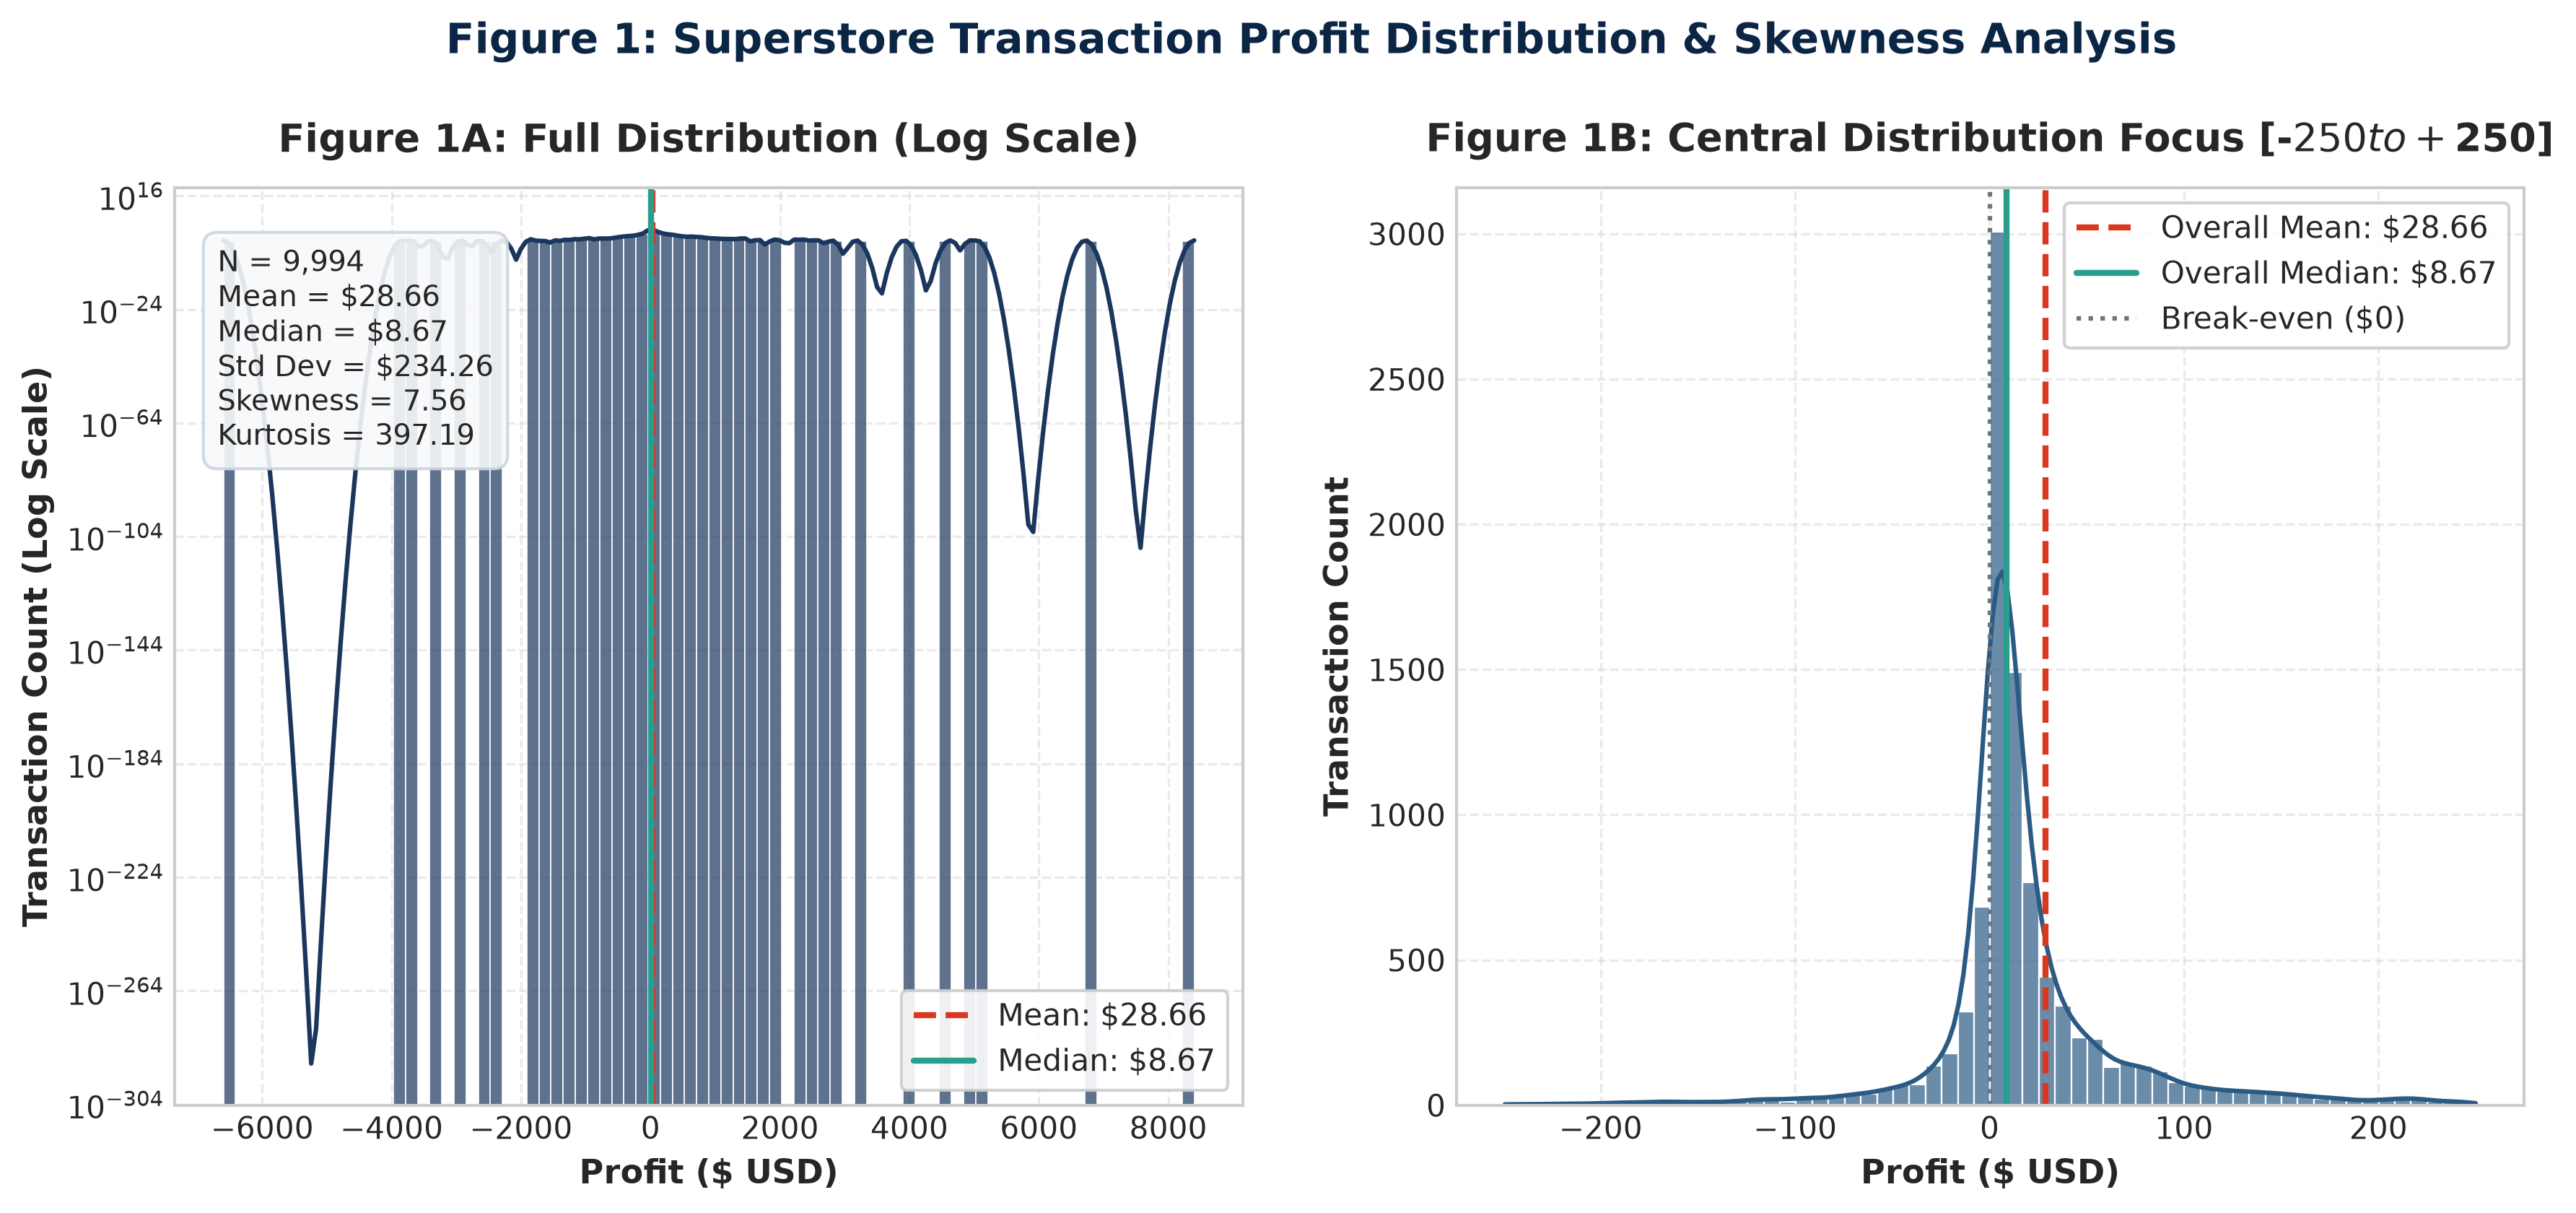

Displaying: 02_discount_vs_profit.png


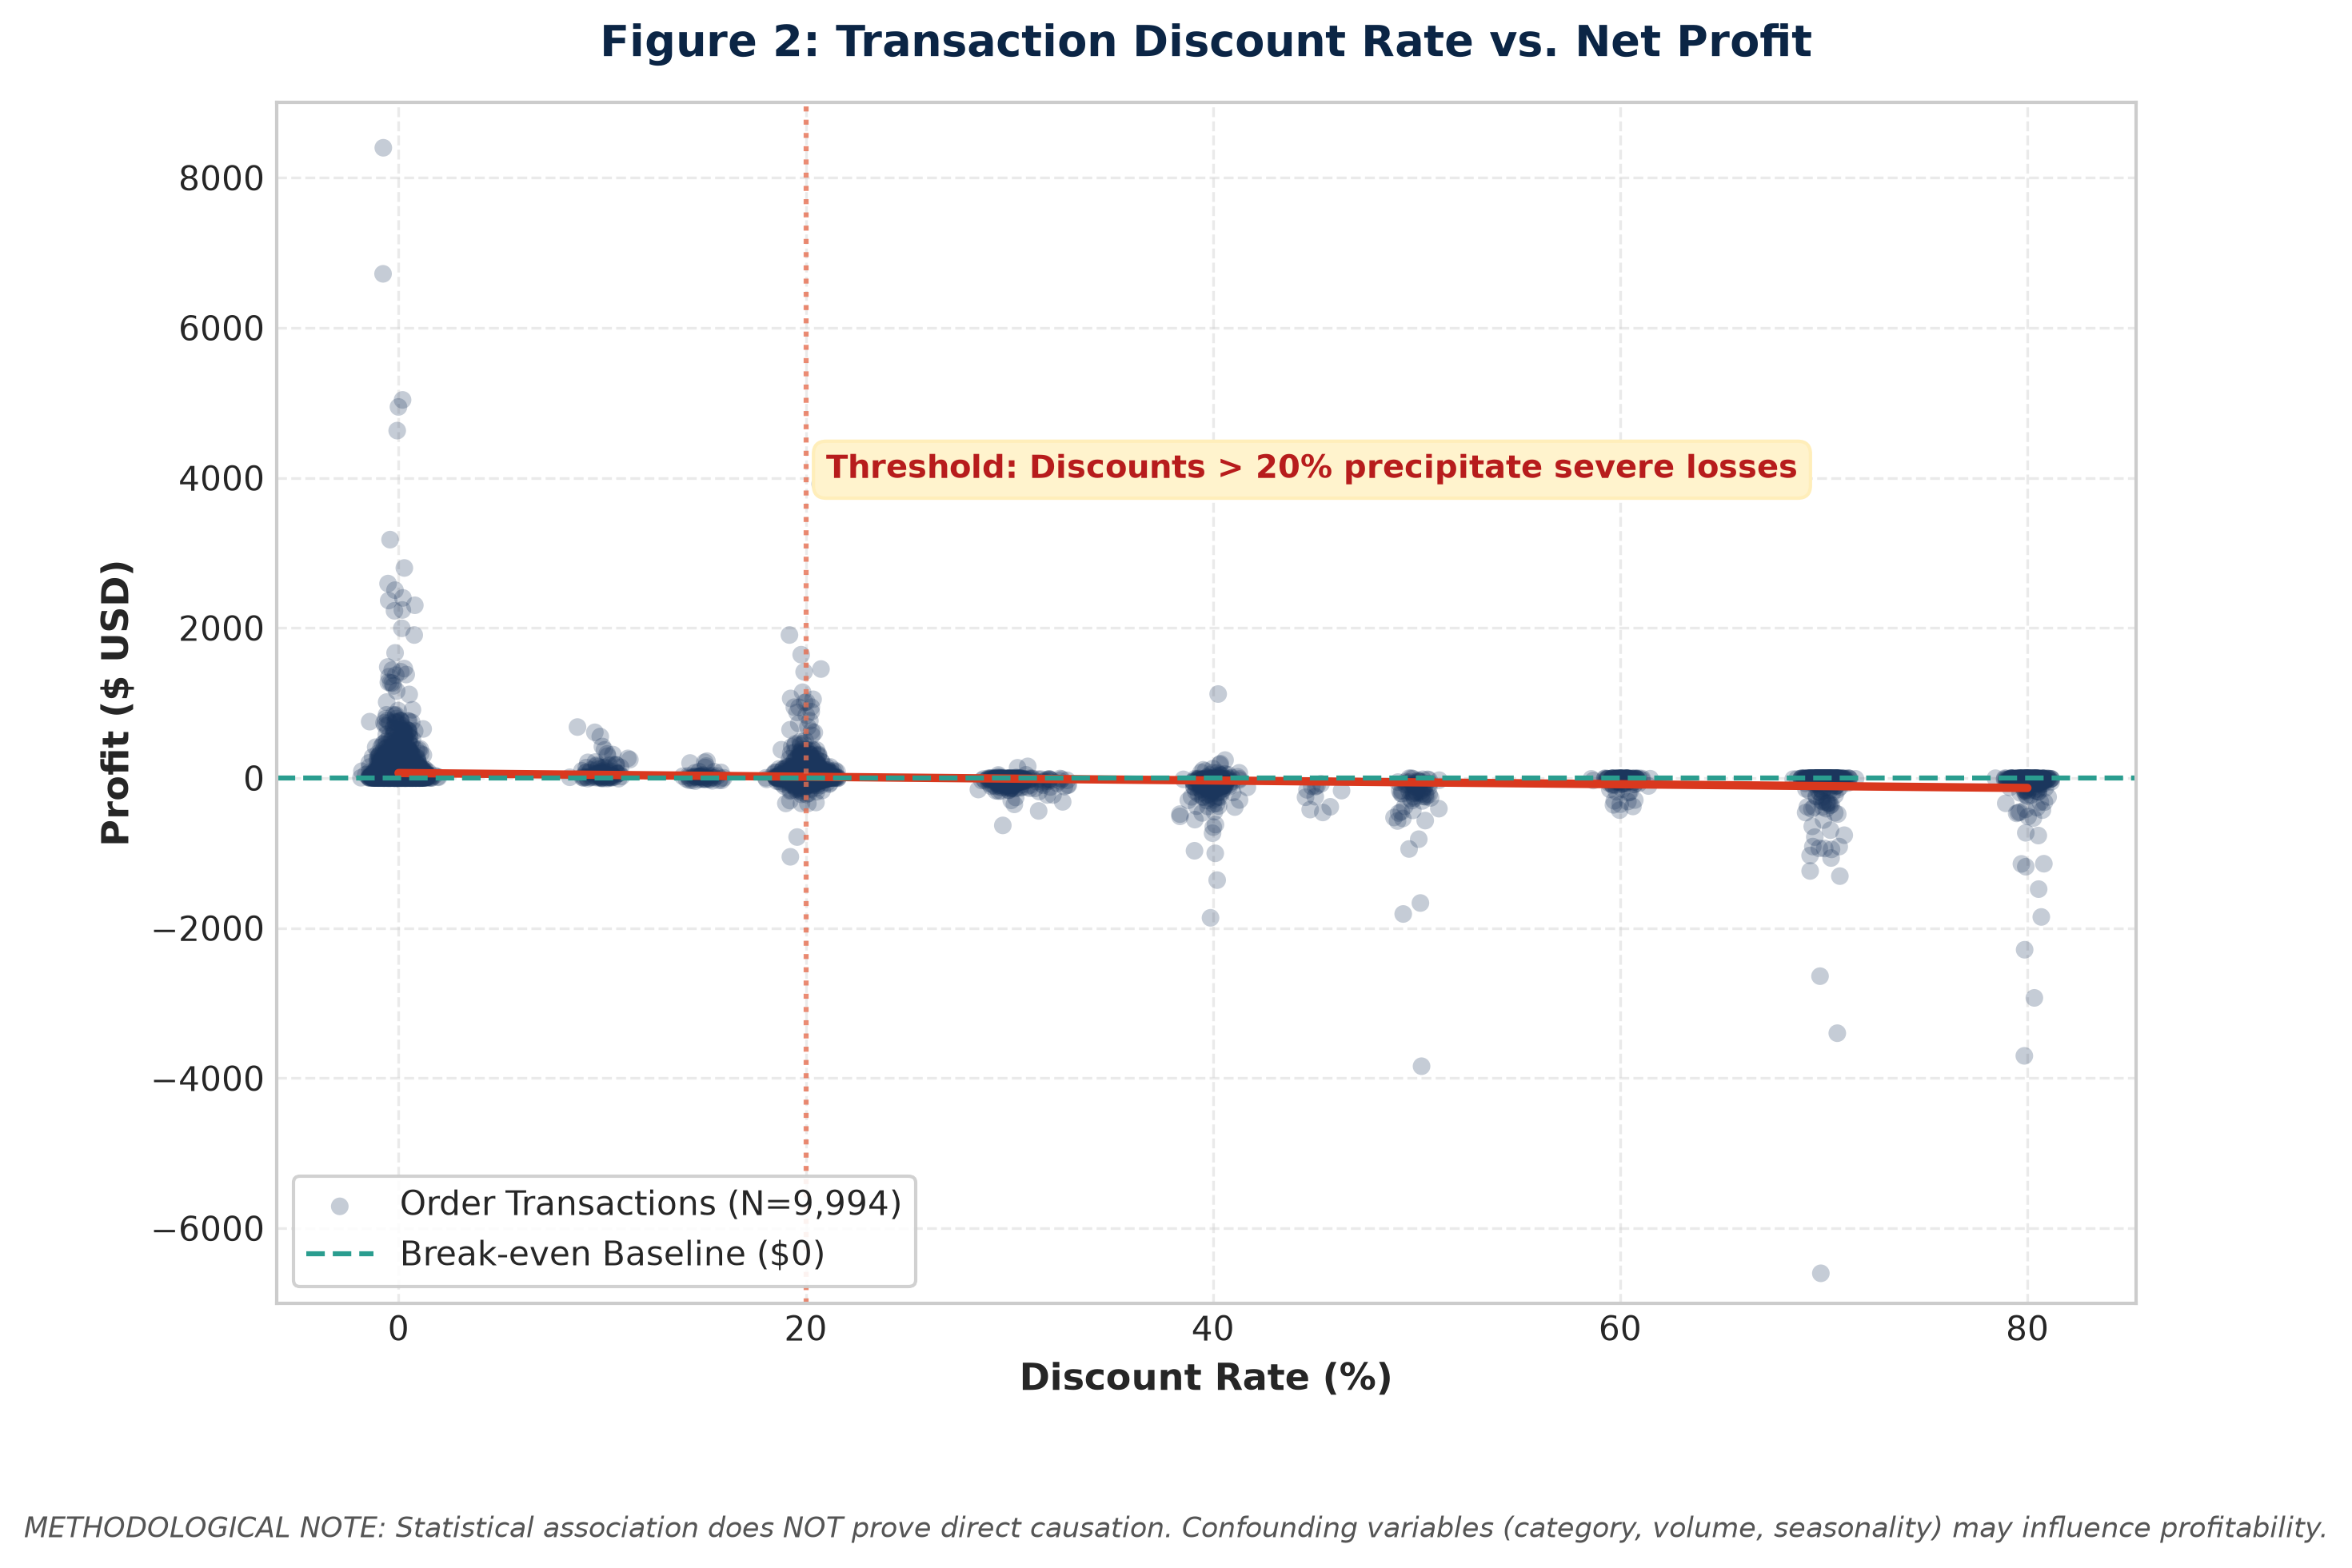

Displaying: 03_group_comparison.png


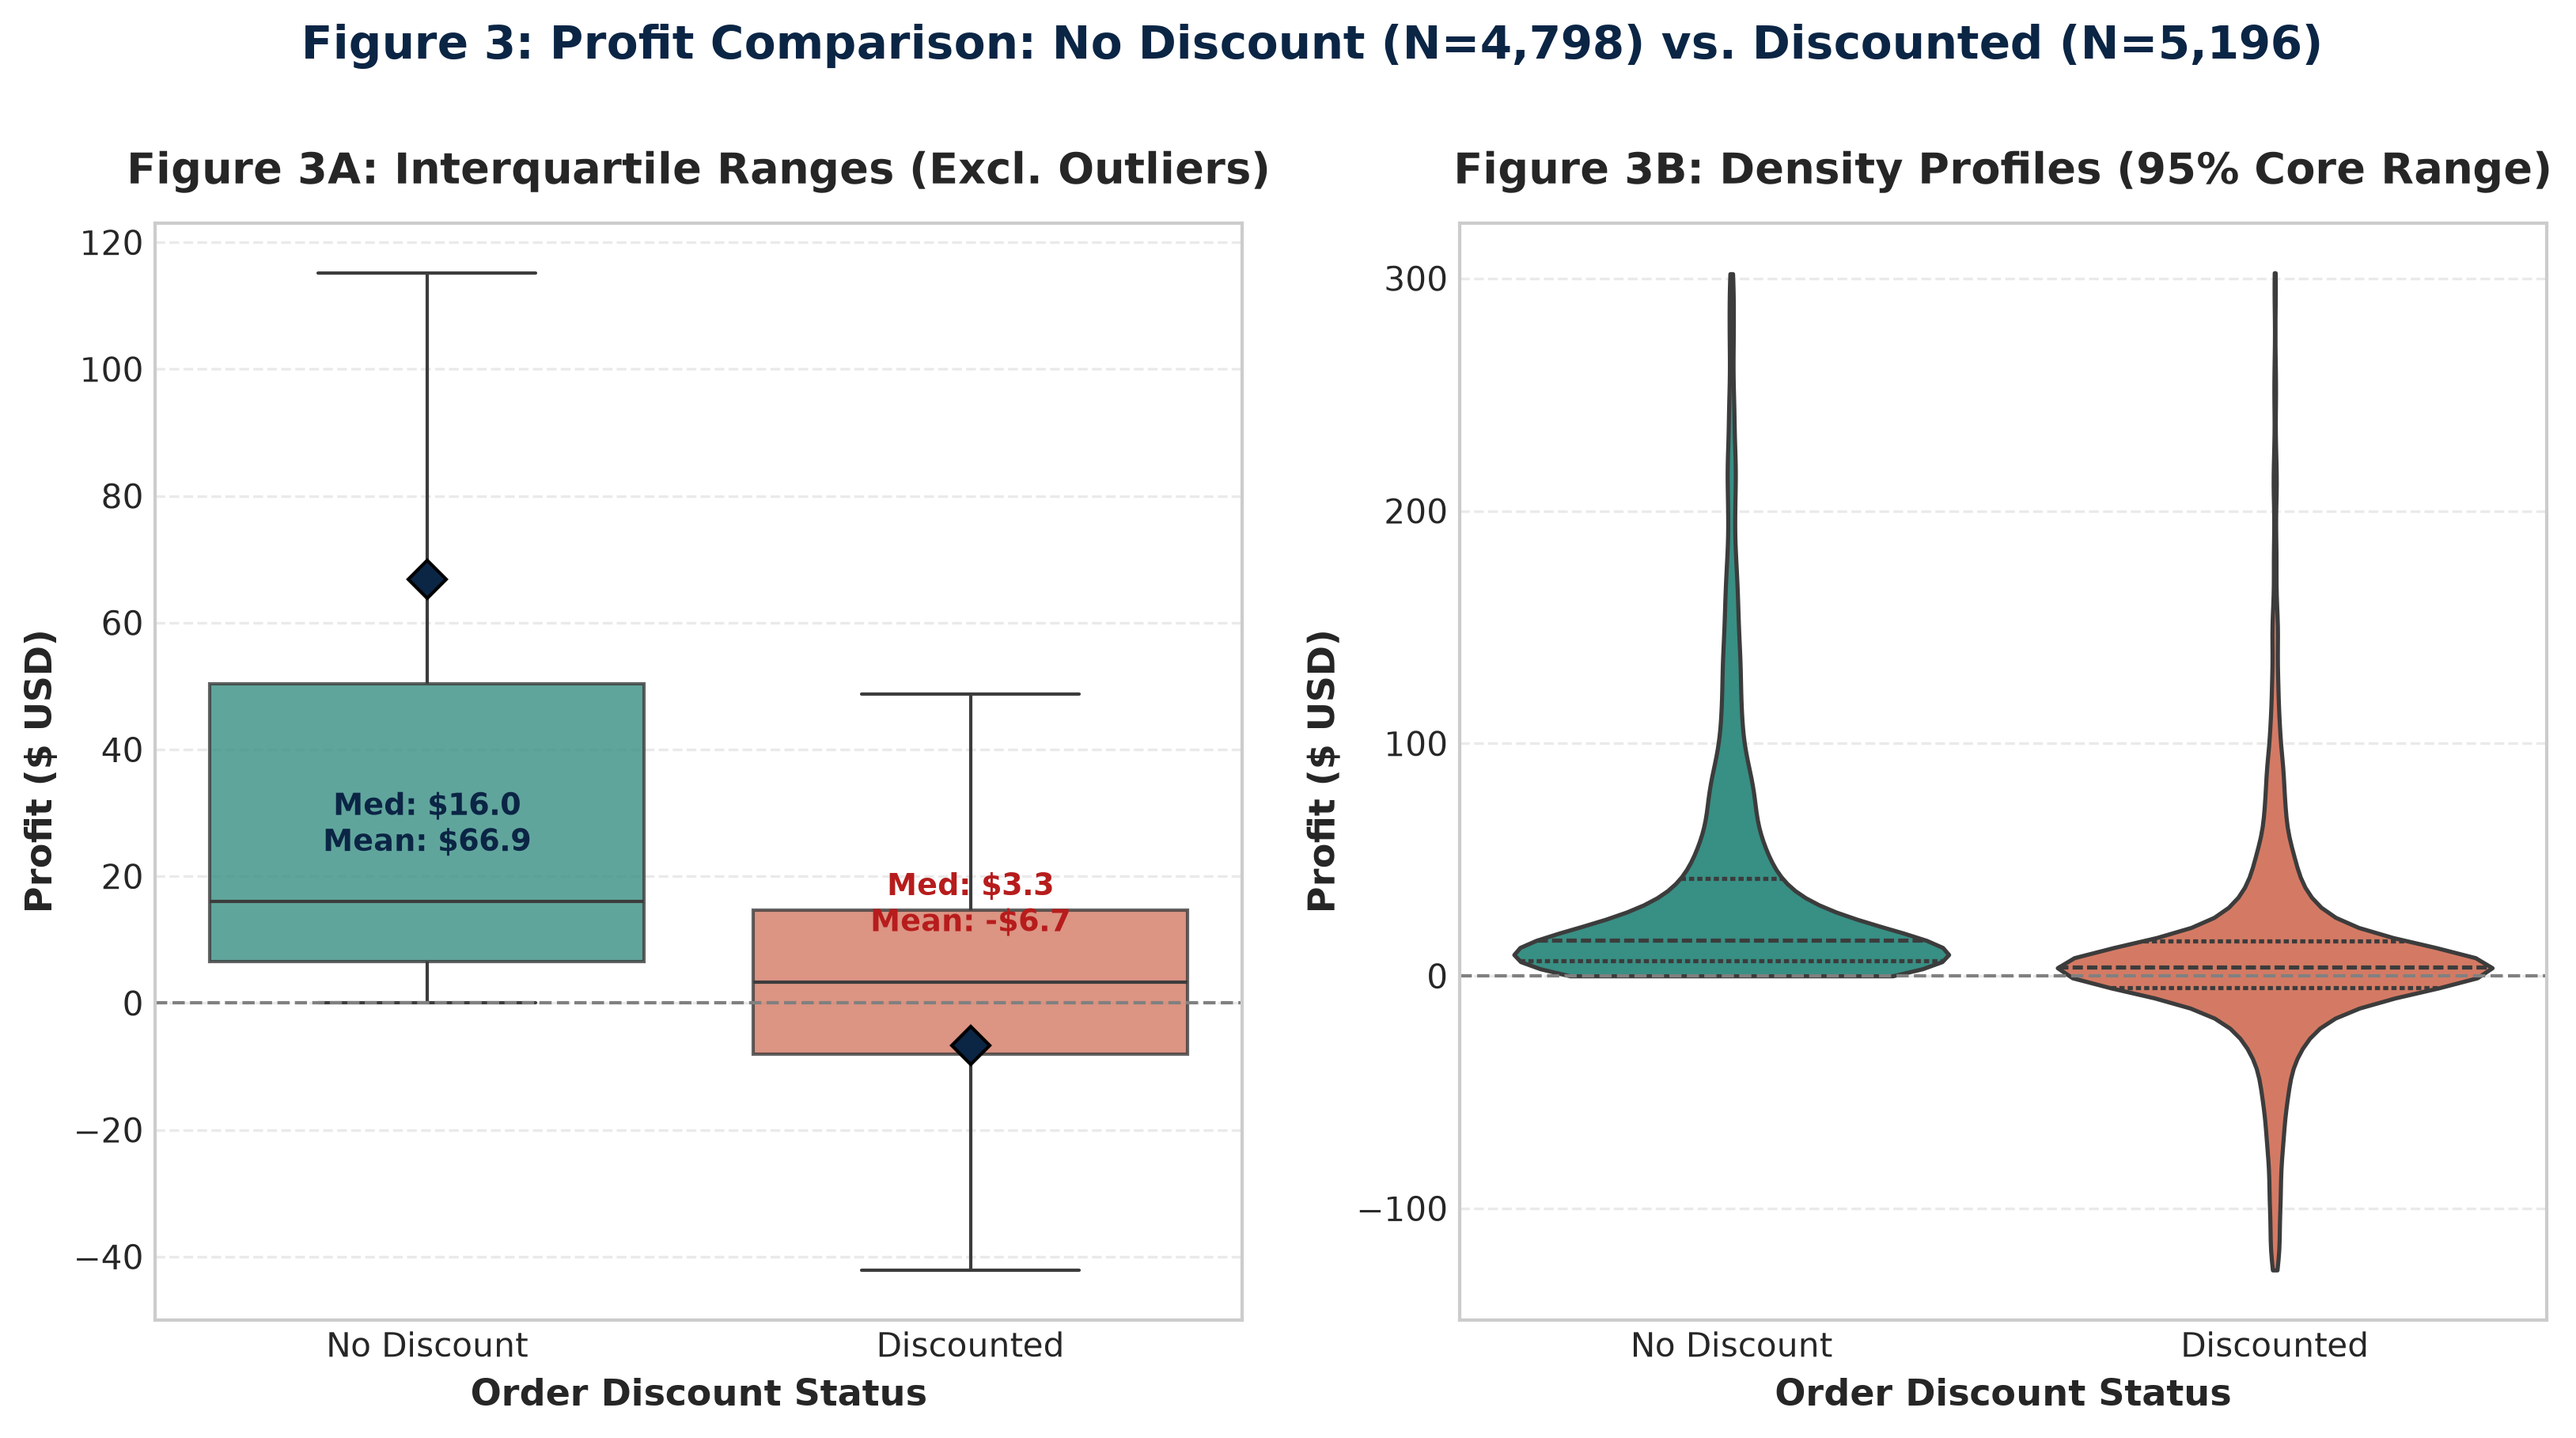

Displaying: 04_category_profit_distribution.png


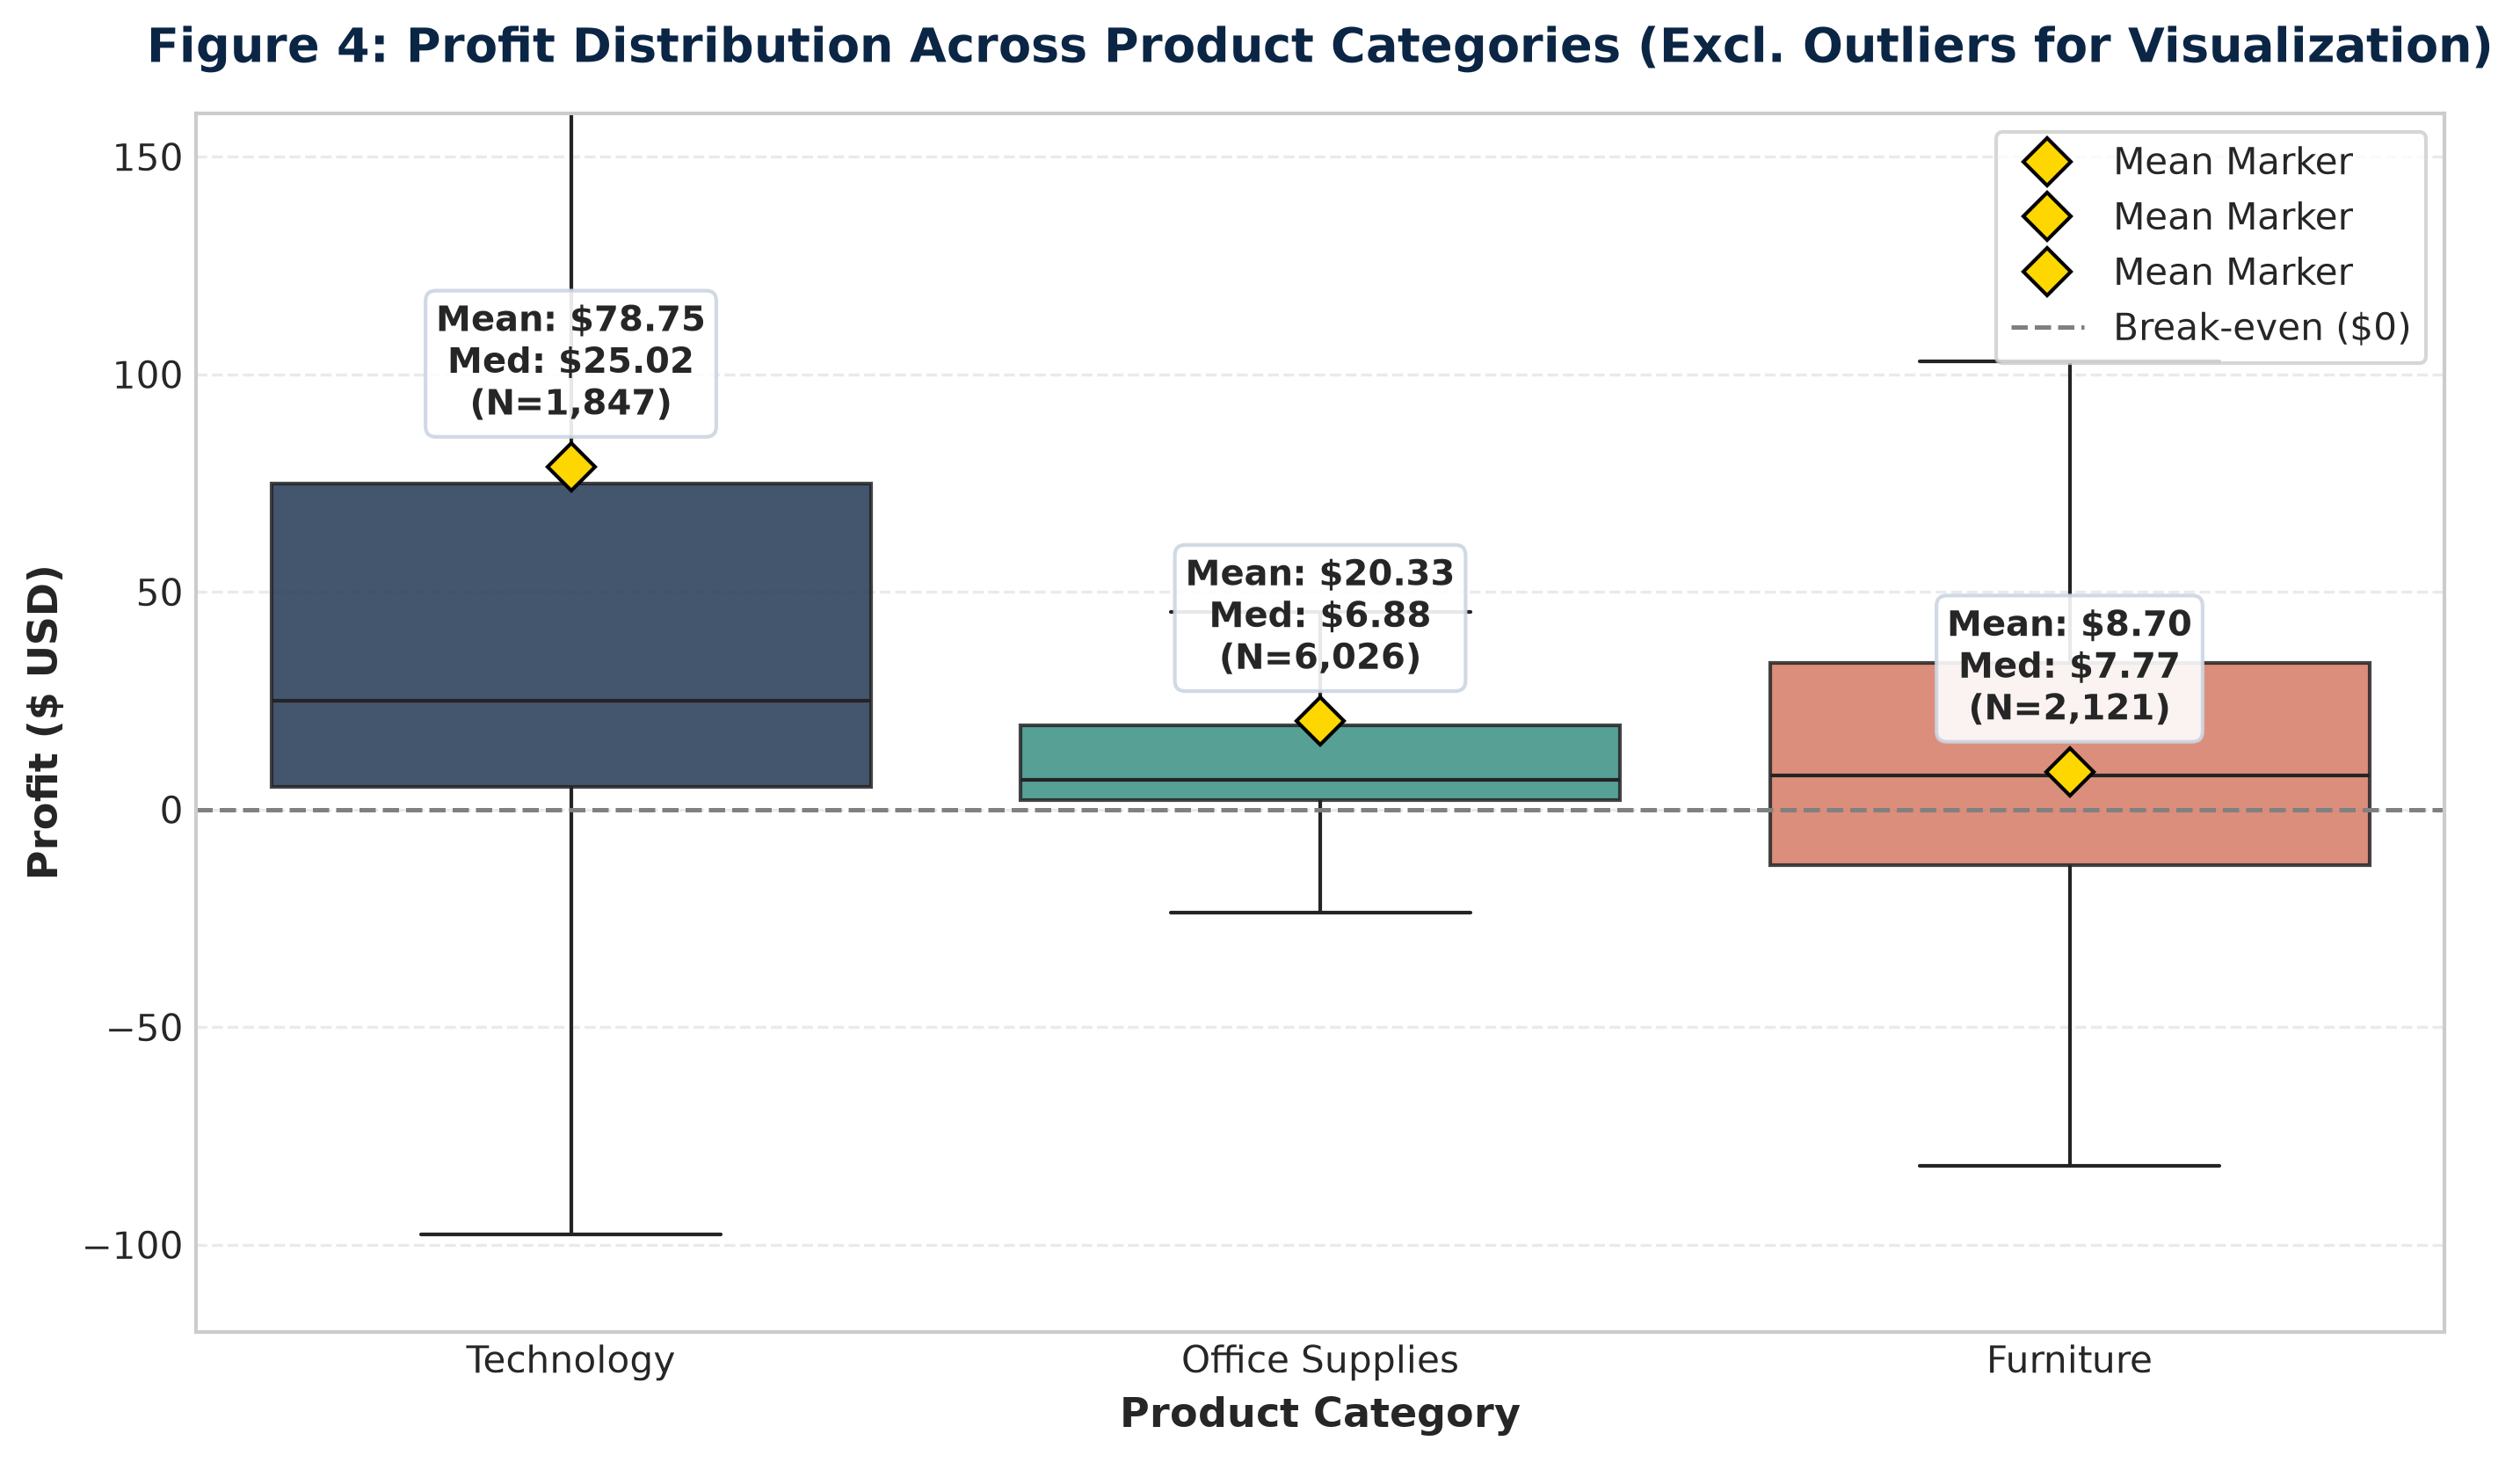

Displaying: 05_anova_comparison.png


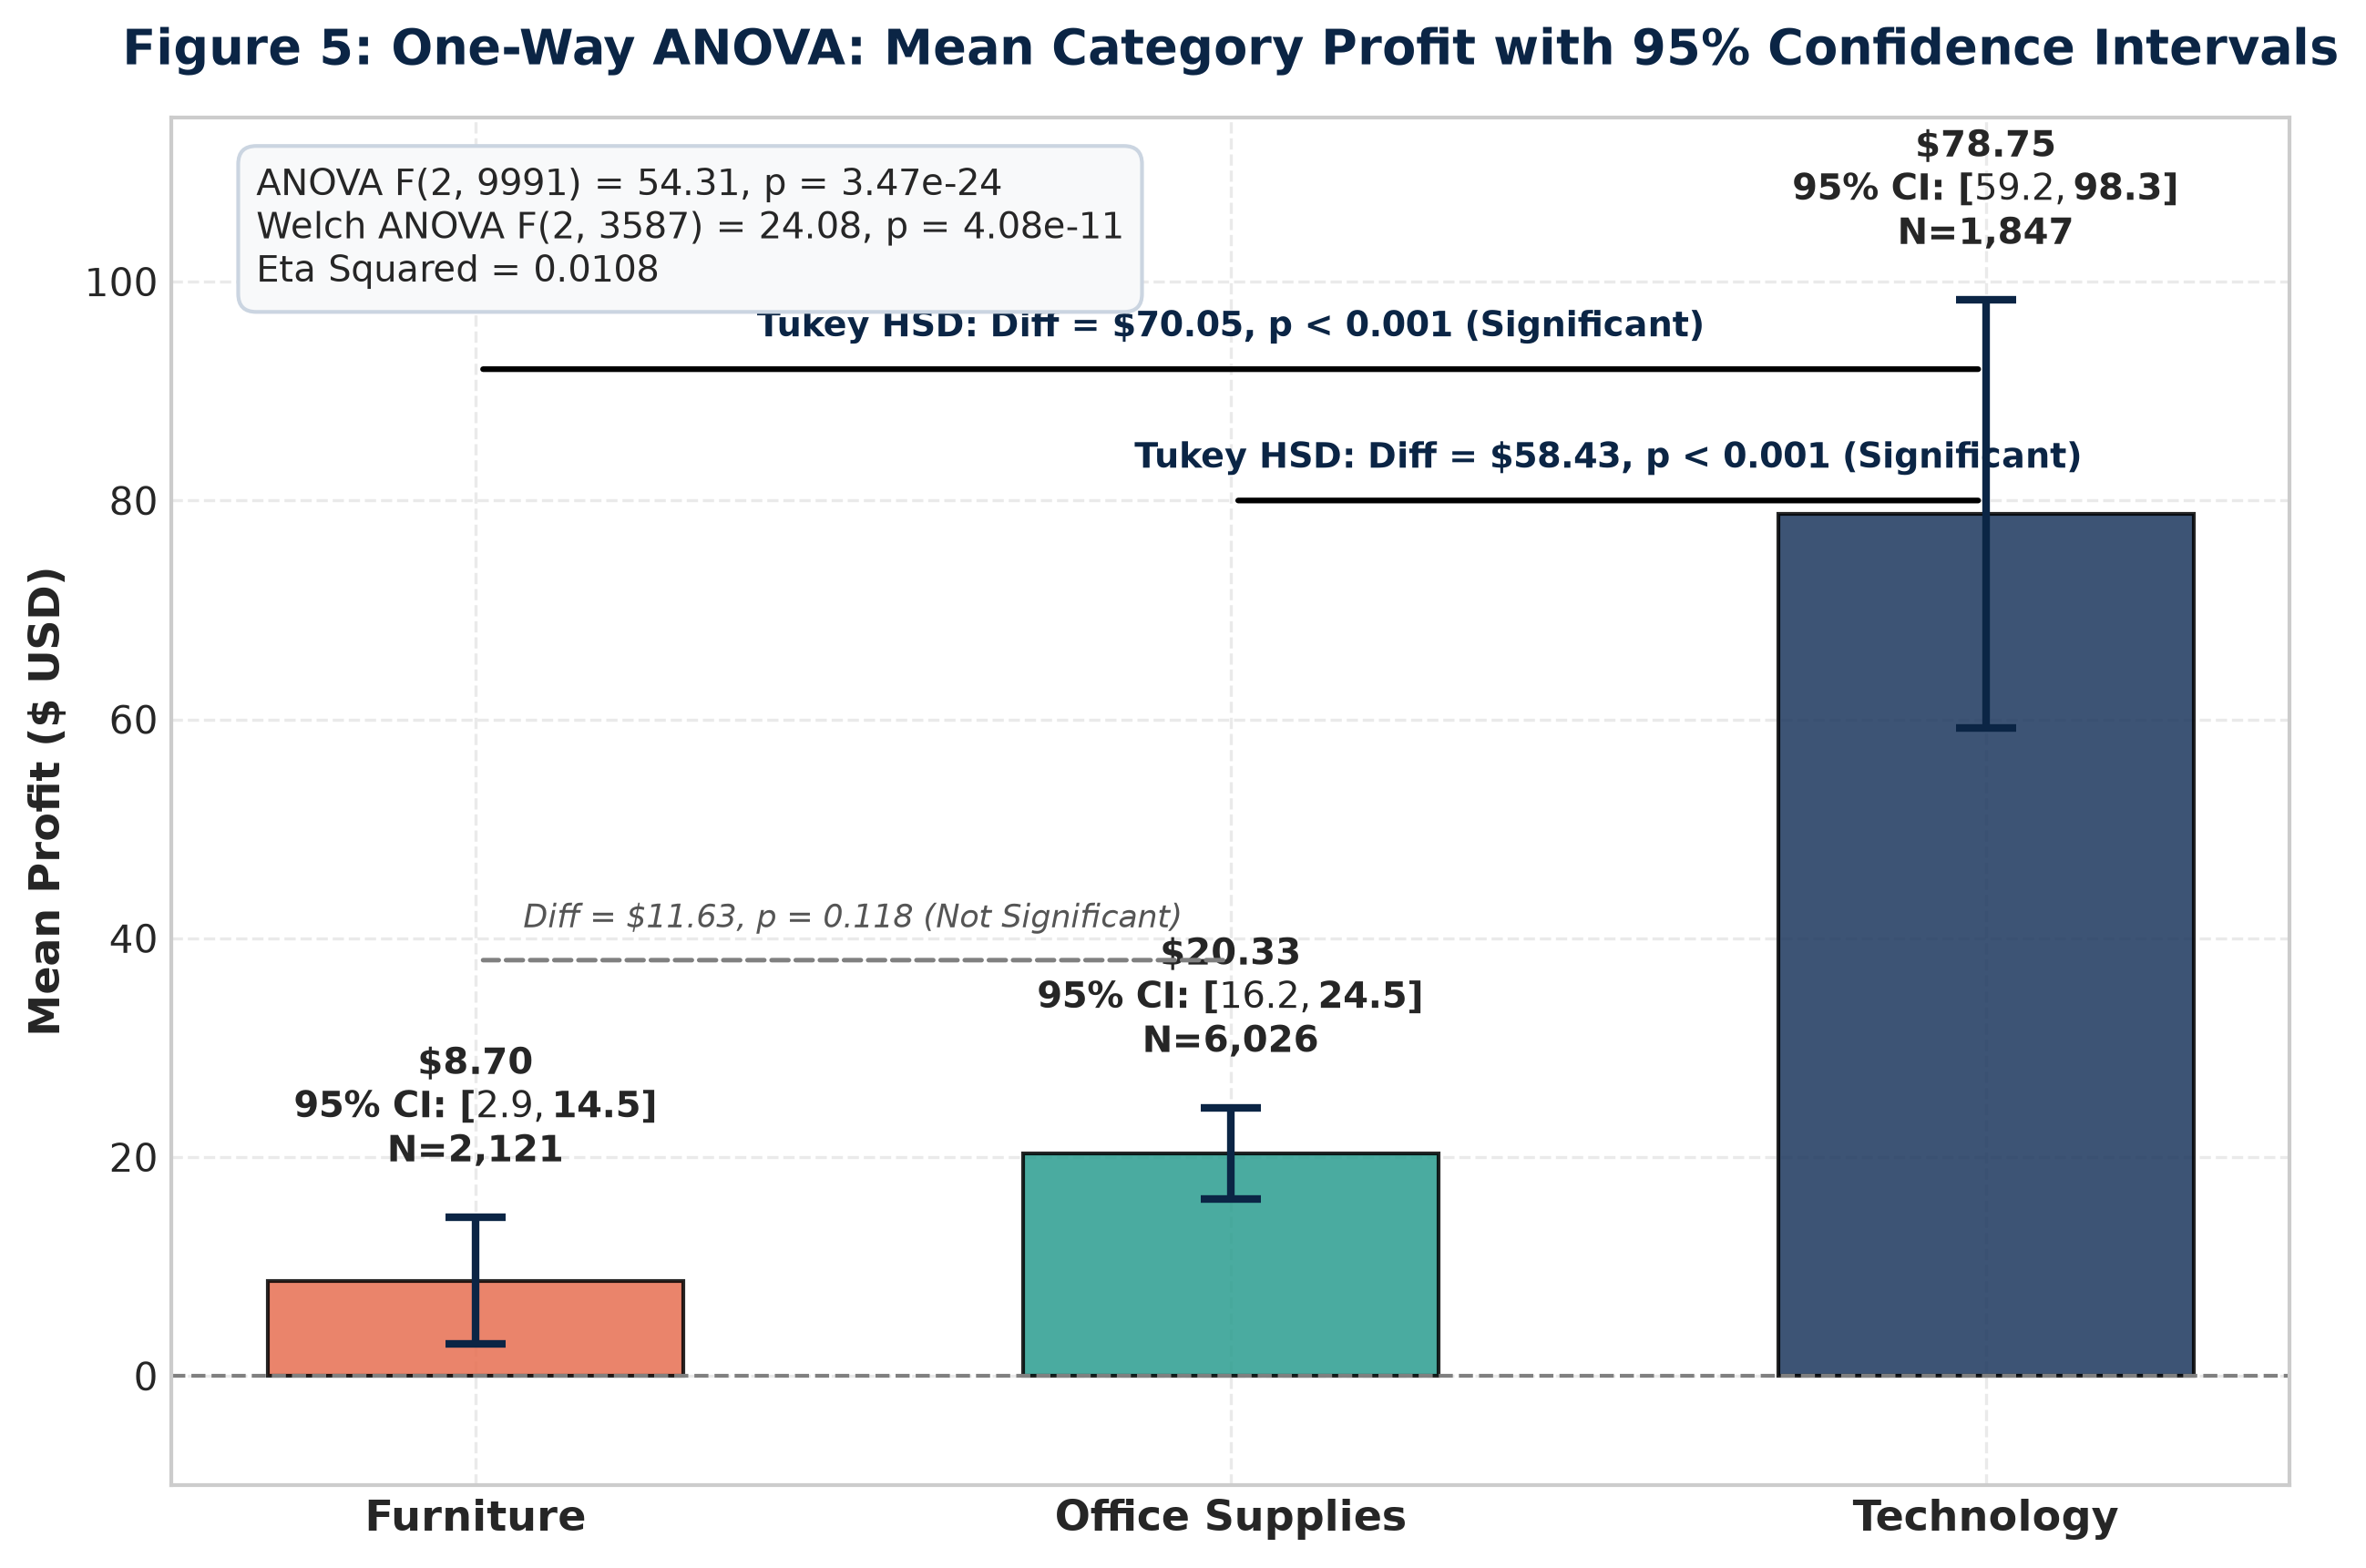

Displaying: 06_contingency_heatmap.png


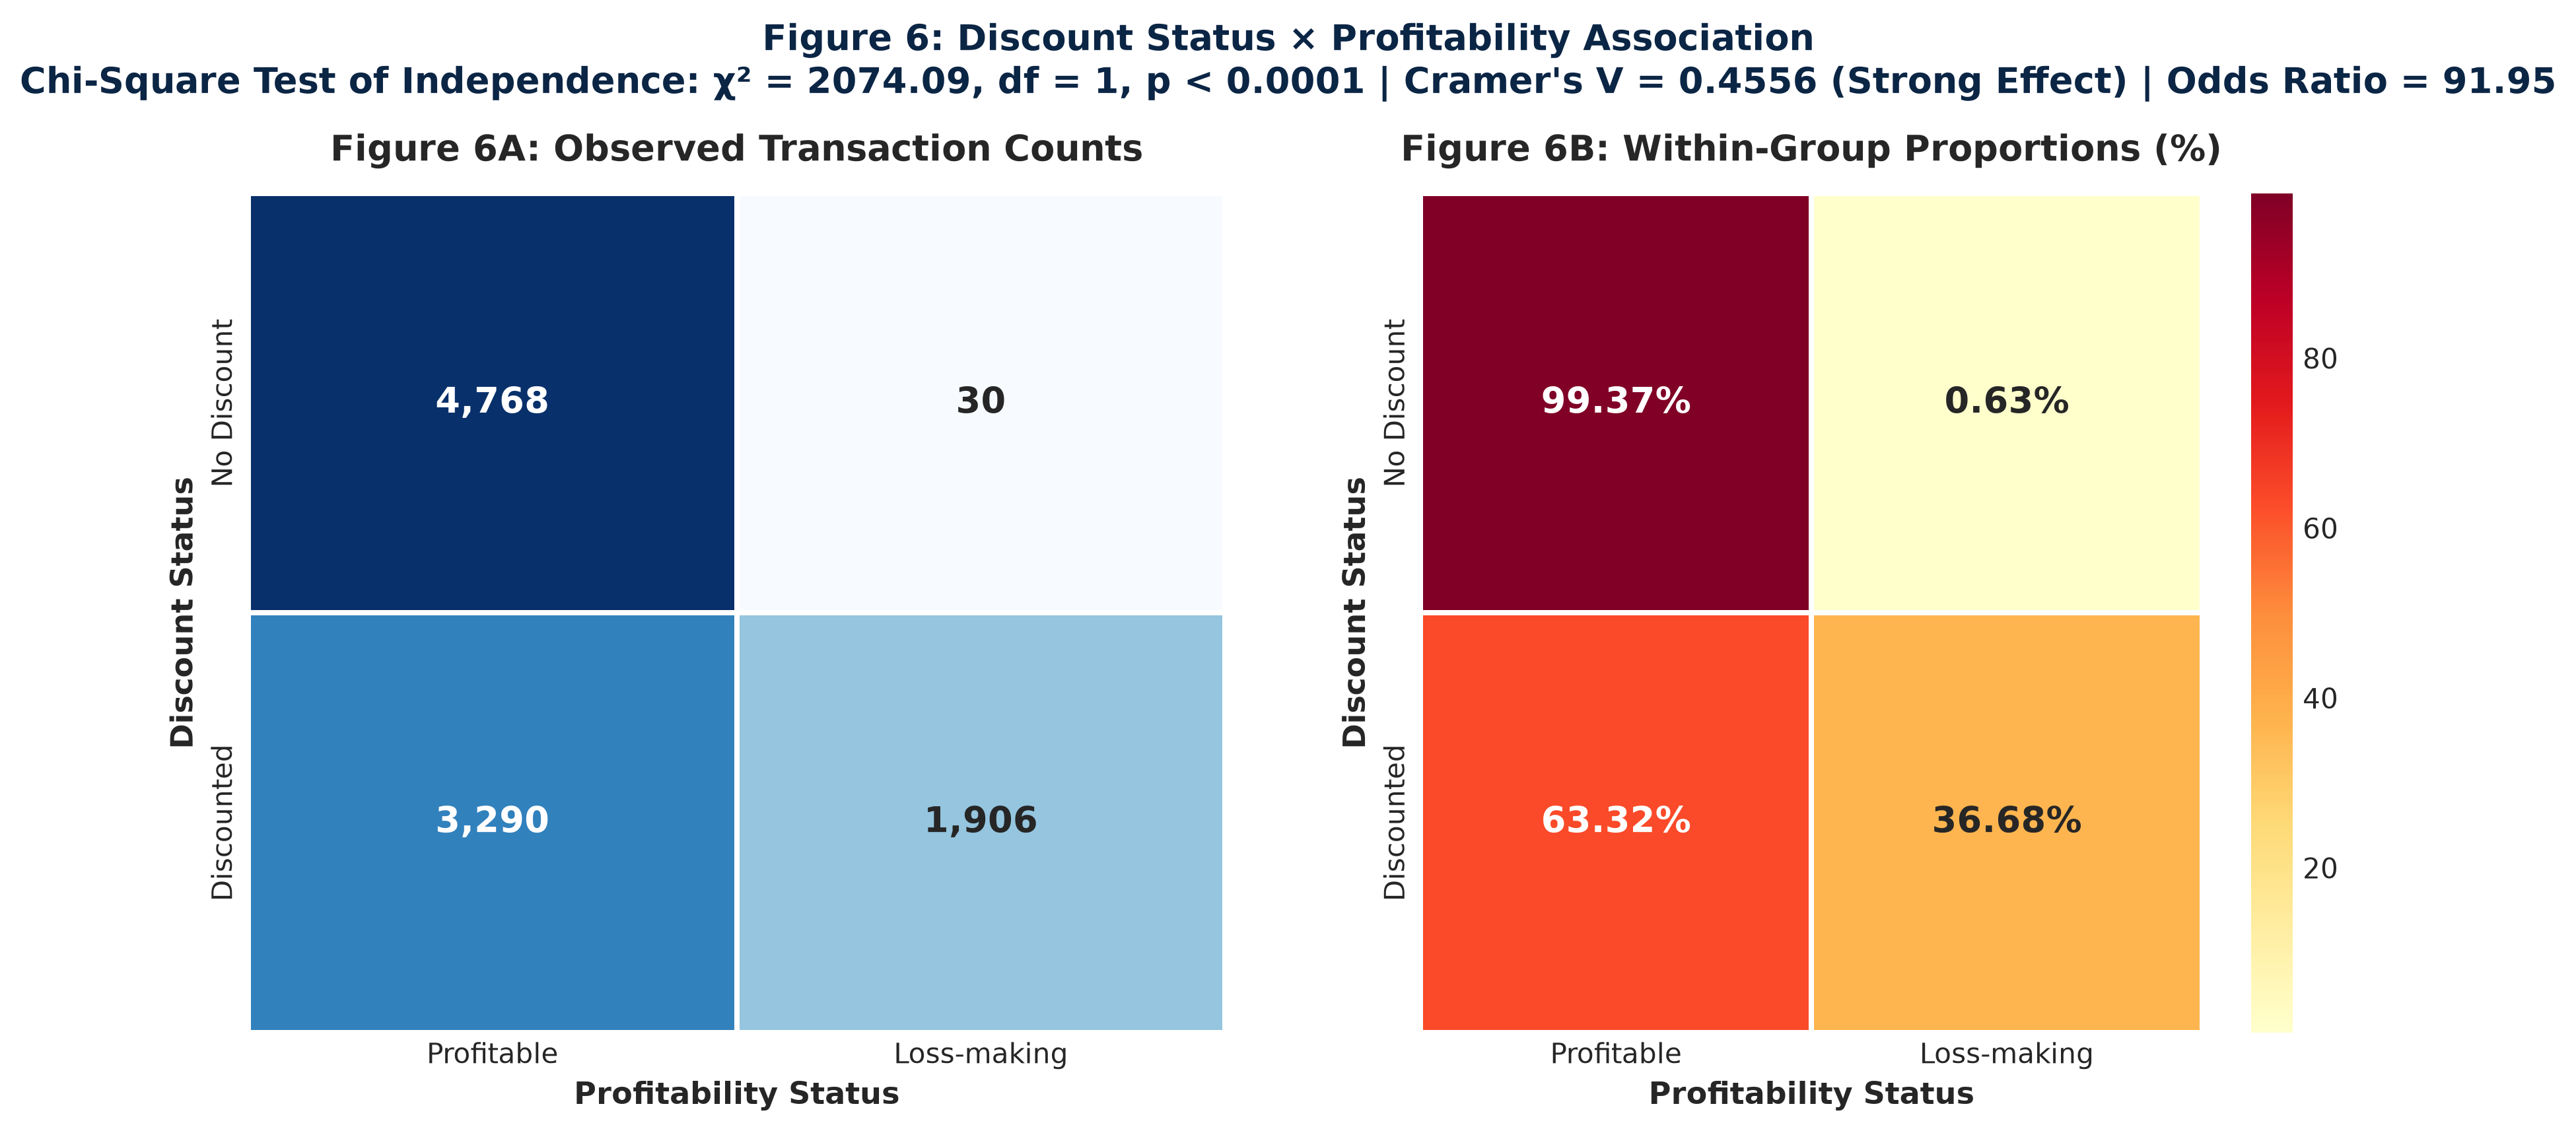

Displaying: 07_confidence_intervals.png


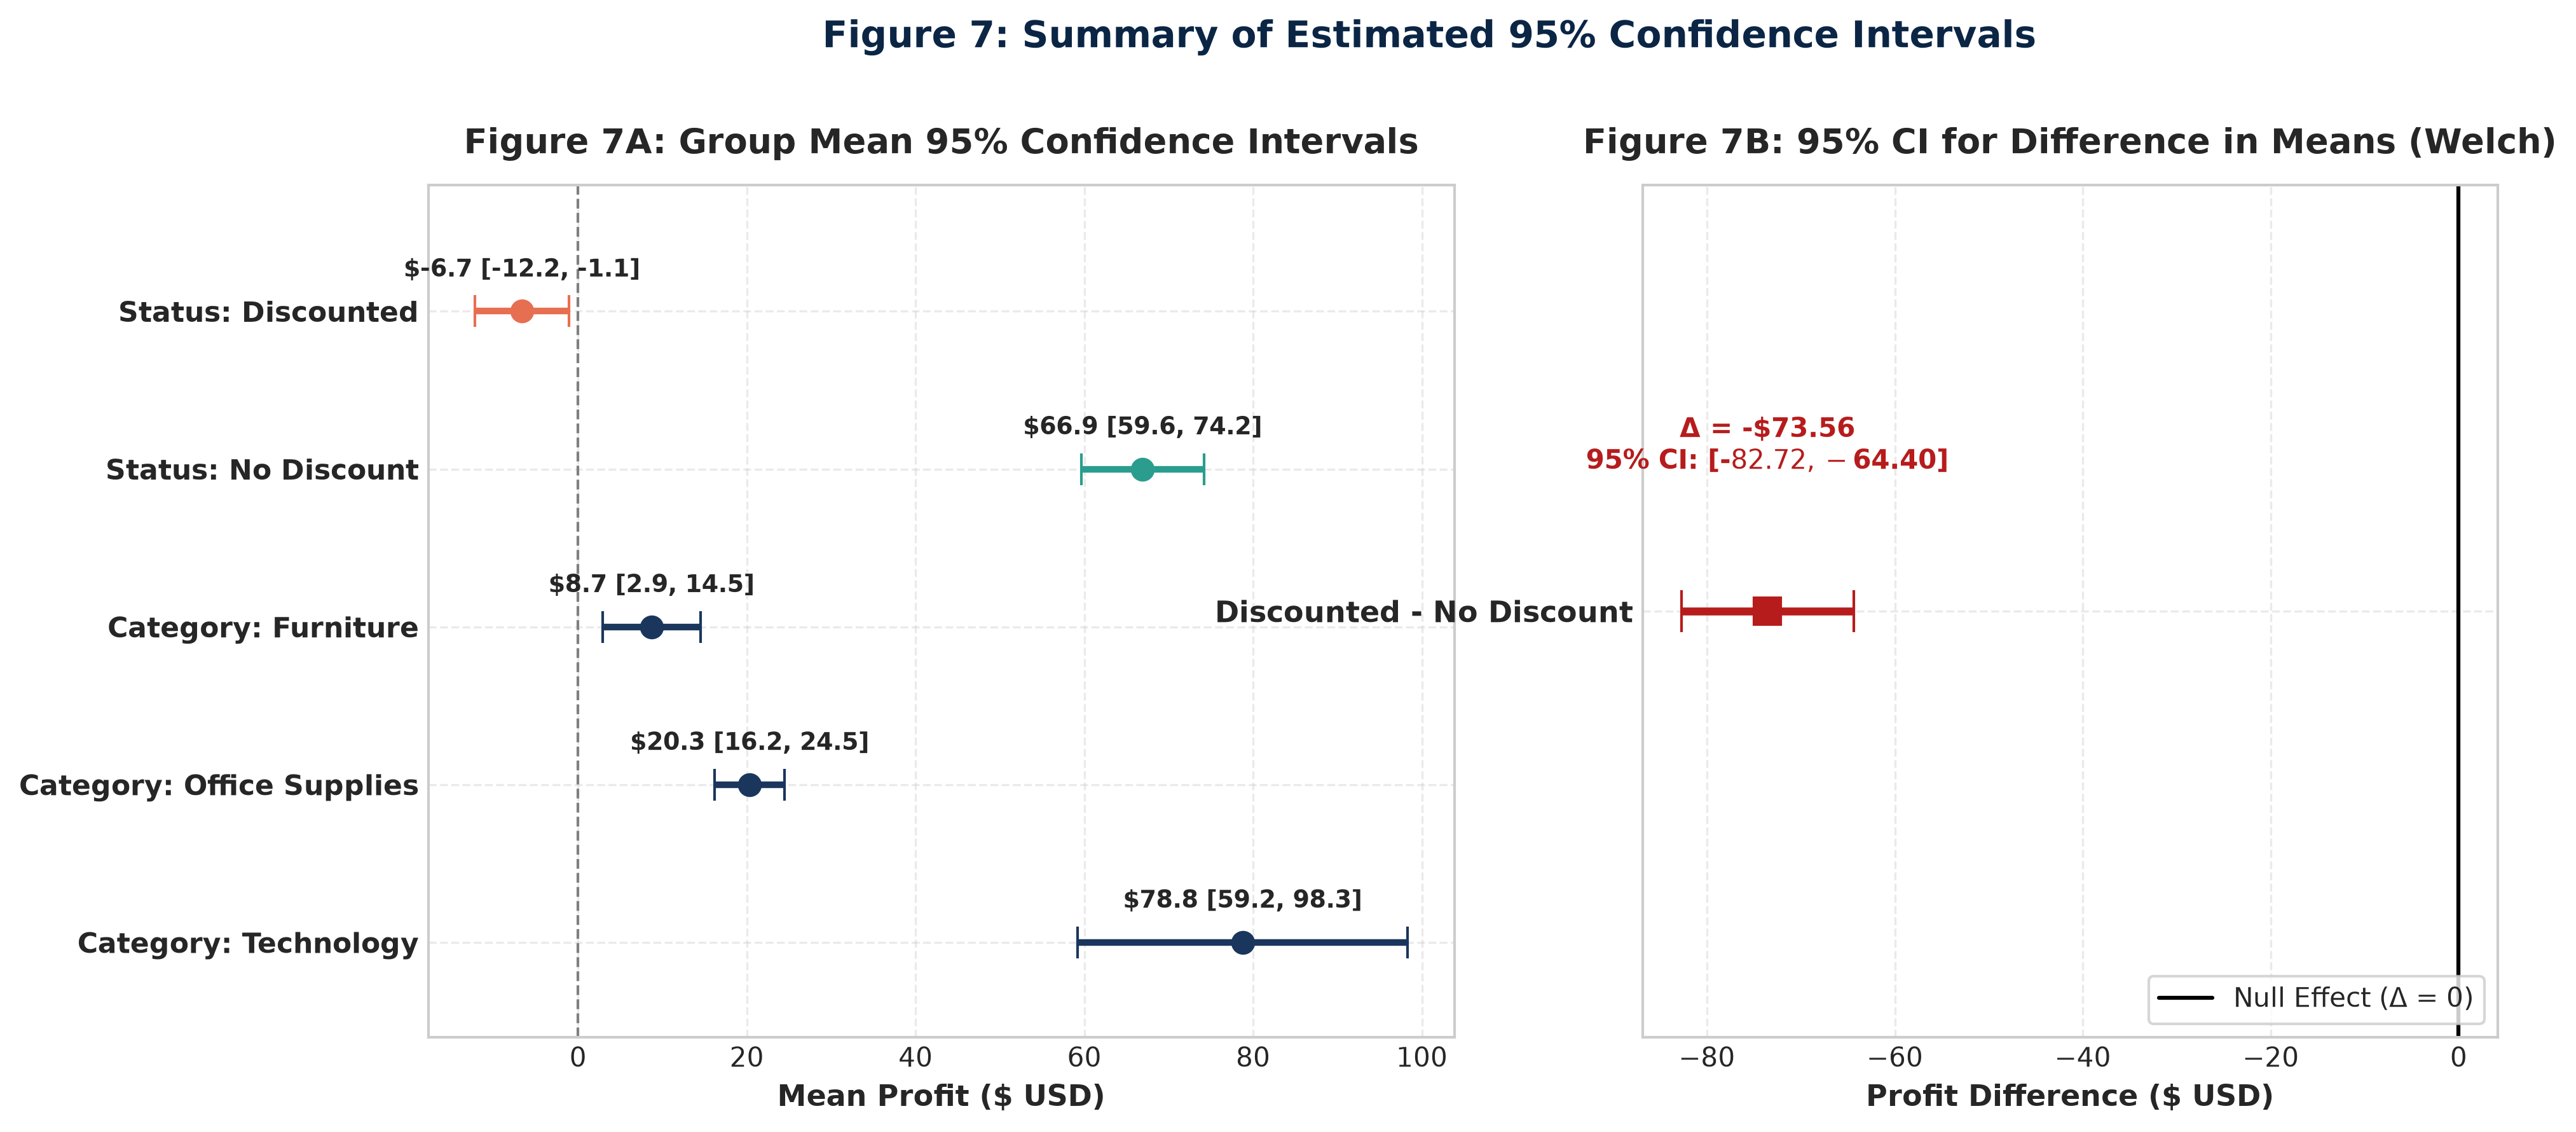

In [14]:
# Display all 7 generated figures
import glob
from IPython.display import Image, display

viz_dir = os.path.join('..', 'visualizations')
if not os.path.exists(viz_dir):
    viz_dir = 'visualizations'

fig_files = sorted(glob.glob(os.path.join(viz_dir, '*.png')))
print(f"[INFO] Found {len(fig_files)} generated statistical figures:")
for fig_path in fig_files:
    print(f"Displaying: {os.path.basename(fig_path)}")
    display(Image(filename=fig_path, width=850))


## 16. Consolidated Statistical Results Table

Below is the consolidated statistical results table summarizing all empirical tests, test statistics, degrees of freedom, p-values, effect sizes, 95% confidence intervals, and final decisions.


In [15]:
res_path = os.path.join('..', 'results', 'statistical_results.csv')
if not os.path.exists(res_path):
    res_path = os.path.join('results', 'statistical_results.csv')

final_results_df = pd.read_csv(res_path)
display(final_results_df)


,Test,Research Question,Statistic,Degrees of Freedom,p-value,Effect Size,95% CI,Decision,Interpretation
0,Welch's Independent t-test (Primary),Does receiving a discount affect average order...,t = -15.7380,9162.24,4.356900e-55,Cohen's d = -0.3179,"[-82.72, -64.40]",Reject H0,Discounted orders have significantly lower ave...
1,Mann-Whitney U Test (Robustness Check),Is profit distribution shifted between discoun...,U = 6266805.5,N/A (Rank sum),0.000000e+00,Rank-biserial r = 0.4973,NaN,Reject H0,Rank-based median profit distribution is signi...
2,One-Way ANOVA (Secondary),Does average profit differ significantly acros...,F = 54.3110,"(2, 9991)",3.469900e-24,Eta squared = 0.0108,Category-specific,Reject H0,Mean profit differs significantly across produ...
3,Welch's ANOVA (Robust Category Test),Does average profit differ across categories u...,F_W = 24.0825,"(2, 3587.09)",4.080200e-11,Eta squared = 0.0108,Category-specific,Reject H0,Category differences remain highly significant...
4,Pearson's Chi-Square Test (Secondary),Is discount status associated with order profi...,Chi2 = 2074.0898,1,0.000000e+00,Cramer's V = 0.4556,Odds Ratio = 92.08,Reject H0,Discounted orders have a drastically higher pr...


## 17. Business Implications, Critical Limitations & Future Scope

### **1. Business Interpretation & Commercial Implications**
1. **The Promotional Trap:** Offering discounts in this retail enterprise does not merely trim margins -- it systematically drives transactions into net losses. Discounted orders lose an average of -\$6.66 per order, whereas undiscounted orders deliver +\$66.90.
2. **Extreme Asymmetry in Loss Incidence:** Undiscounted orders have an extraordinary 99.37% profit rate, while discounted orders fail to break even in 36.68% of transactions (an odds ratio of 91.95).
3. **Threshold Effects:** Transactions with discounts above 20% experience severe downside risks. Deep discounting (>50%) produces a 100% loss rate in this dataset.
4. **Category Nuances:** Technology products generate the highest mean profit (\$78.75), while Furniture generates only \$8.70. High discounting in Furniture creates severe operational deficits.

---

### **2. Crucial Methodological Limitations**
1. **Observational Data vs. Causation:** This dataset consists of observational transactions, not a randomized controlled trial (A/B experiment). Discounter orders may differ in product mix, regional pricing tiers, or customer price sensitivity. **Statistical association does not prove direct causation.**
2. **Missing Fixed Cost and Customer Lifetime Value (CLV):** The dataset records order-level accounting profit but lacks customer acquisition costs (CAC), repeat purchase rates, or long-term retention metrics. A discount that loses money upfront might theoretically be justified if it acquires a high-CLV repeat customer.
3. **Unobserved Confounders:** Category-level margins, supplier rebates, shipping freight contracts, and regional sales quotas are unobserved variables that likely confound the discount-profit relationship.

---

### **3. Future Analytical Directions**
- **Econometric Causal Inference:** Apply Propensity Score Matching (PSM) and Instrumental Variables (IV) to isolate causal discount elasticity.
- **Multivariate Regression & Machine Learning:** Fit regularized models (Lasso/Ridge, Gradient Boosting) to estimate non-linear discount elasticity curves per sub-category.
- **Customer Cohort LTV Tracking:** Link order profitability to longitudinal customer repeat transaction behavior.


## 18. Final Internship Conclusion

| Hypothesis Test | Research Question | Test Statistic | p-value | Effect Size | Decision | Commercial Implication |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Welch's t-test (Primary)** | Discount vs. Mean Profit | $t = -15.7380$ | $4.36 \times 10^{-55}$ | $d = -0.3179$ | **Reject $H_0$** | Discounted orders generate \$73.56 lower mean profit. |
| **Mann-Whitney U** | Distributional Robustness | $U = 6,266,805.5$ | $< 0.0001$ | $r = 0.4973$ | **Reject $H_0$** | Findings are highly robust to extreme outliers and skewness. |
| **One-Way ANOVA** | Category Mean Profit | $F = 54.3110$ | $3.47 \times 10^{-24}$ | $\eta^2 = 0.0108$ | **Reject $H_0$** | Profit differs significantly across categories (Technology leads). |
| **Tukey HSD Post-Hoc** | Pairwise Category Differences | Multiple | Technology $p < 0.001$ | Group Diffs | **Partial Reject** | Technology beats Furniture & Office; Furniture equals Office Supplies. |
| **Chi-Square Test** | Discount vs. Loss Association | $\chi^2 = 2074.09$ | $< 10^{-300}$ | $V = 0.4556$ | **Reject $H_0$** | Discounting escalates loss-making odds by 92-fold. |

This statistical study demonstrates the critical value of rigorous hypothesis testing over simplistic exploratory aggregations. Management must institute a maximum discount threshold (recommended $\le 20\%$), establish category-specific approval gates, and replace blanket discounting with targeted, margin-protected loyalty incentives.
